# Lecture 13 live tutorial: from a reaction entry to dynamic metabolic predictions

We ask the same practical question repeatedly: **what additional information changes the prediction?** Read a real reconstruction and change one uptake bound. Then add environmental dynamics, culture protocols, protein budgets, chemical potentials, enzyme capacities and selected kinetics. Finally retain internal pools and growing machinery while optimizing their control.

The opening follows the lecturer's April 2022 FBA notebook. Both archived BiGG models are included. Every model loads locally. Small declared models make the later constraints inspectable.

**Live route:** Sections 1–4 introduce the API and nutrient experiment. Sections 5–14 contain optional FBA extensions and model comparisons. Sections 15–18 connect cart balancing, subsystem regulation and whole-cell growth objectives. Run the setup first. The longer optimization comparisons use saved, verified results and include an explicit recomputation switch. The short allocation experiment really solves an optimization during the notebook run.

The biological coefficients of the small teaching models are illustrative unless a source and equation are stated. Read the assumptions beside each experiment before interpreting a curve.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra
from IPython.display import display

HERE = Path.cwd()
assert (HERE / 'models' / 'iJO1366.json').exists(), 'Open this notebook inside its supplied notebooks folder.'
sys.path.insert(0, str(HERE.parent))  # the supplied ecology module is a sibling folder
import lecture13_models as demo
import tutorial_figures as figures
import fec_tracking

print('COBRApy:', cobra.__version__)
print('The model files and all helper code are local.')
import json
from IPython.display import SVG
from scipy.linalg import expm
import culture_protocol
import thermodynamics
import enzyme_capacity
import allocation_control
import growth_control


COBRApy: 0.32.1
The model files and all helper code are local.


## 1. Inspect a reaction, a metabolite, and one stoichiometric coefficient

A reconstruction is a collection of identifiable objects. A reaction column says which metabolites are consumed and produced. It does not yet specify the reaction's regulatory rate law. First open the real iJO1366 model and inspect its size.

In [2]:
model = demo.load_model('iJO1366')
model

Name,iJO1366
Memory address,3019fcd70
Number of metabolites,1805
Number of reactions,2583
Number of genes,1367
Number of groups,0
Objective expression,1.0*BIOMASS_Ec_iJO1366_core_53p95M - 1.0*BIOMASS_Ec_iJO1366_core_53p95M_reverse_5c8b1
Compartments,"cytosol, extracellular space, periplasm"


In [3]:
pfk = model.reactions.get_by_id('PFK')
pfk

Reaction identifier,PFK
Name,Phosphofructokinase
Memory address,0x305b80310
Stoichiometry,"atp_c + f6p_c --> adp_c + fdp_c + h_c ATP C10H12N5O13P3 + D-Fructose 6-phosphate --> ADP C10H12N5O10P2 + D-Fructose 1,6-bisphosphate + H+"
GPR,b3916 or b1723
Lower bound,0.0
Upper bound,1000.0


**Read the PFK column before optimizing.** Negative coefficients are consumed. Positive coefficients are produced. In the table, the proton is displayed as H⁺. The identifiers retain their compartment suffixes: `atp_c` is cytosolic ATP.

In [4]:
display(demo.reaction_entries(pfk))
print('ATP coefficient in PFK:', pfk.get_coefficient('atp_c'))
print('Current PFK bounds:', pfk.bounds)

,id,name,coefficient,role
0,adp_c,ADP C10H12N5O10P2,1.0,produced
1,atp_c,ATP C10H12N5O13P3,-1.0,consumed
2,f6p_c,D-Fructose 6-phosphate,-1.0,consumed
3,fdp_c,"D-Fructose 1,6-bisphosphate",1.0,produced
4,h_c,H⁺,1.0,produced


ATP coefficient in PFK: -1.0
Current PFK bounds: (0.0, 1000.0)


In [5]:
atp = model.metabolites.get_by_id('atp_c')
display(atp)
print('Number of reactions containing cytosolic ATP:', len(atp.reactions))
print('Some reaction identifiers:', sorted(r.id for r in atp.reactions)[:12])

Metabolite identifier,atp_c
Name,ATP C10H12N5O13P3
Memory address,0x3043f0cd0
Formula,C10H12N5O13P3
Compartment,c
In 359 reaction(s),"2AGPEAT180, 3KGK, PGP140abcpp, FRULYSK, GTHRDabcpp, 2AGPEAT181, ASPTRS, ADOCBIK, GTHS, MPTAT, CBIAT, METTRS, CLIPAabctex, XYLabcpp, AP4AS, GMHEPAT, PFK, PPAKr, METabcpp, PACCOAL, PFK_2, FCLK,..."


Number of reactions containing cytosolic ATP: 359
Some reaction identifiers: ['14GLUCANabcpp', '2AGPEAT120', '2AGPEAT140', '2AGPEAT141', '2AGPEAT160', '2AGPEAT161', '2AGPEAT180', '2AGPEAT181', '2AGPGAT120', '2AGPGAT140', '2AGPGAT141', '2AGPGAT160']


## 2. Inspect the objective and the complete biomass column

The biomass reaction combines precursor demand with energy and other bookkeeping. Its flux is the specific growth objective. Its coefficients are **not mass fractions**. In particular, large ATP, ADP, H₂O and H⁺ terms describe energy-associated conversions. Ranking by absolute coefficient answers which entries are numerically largest in this reaction's chosen normalization.

In [6]:
print(model.objective.expression)
biomass_reaction = next(r for r in model.reactions if r.objective_coefficient != 0)
print('Biomass reaction:', biomass_reaction.id)
biomass = demo.biomass_entries(model)
print('Number of nonzero biomass entries:', len(biomass))
display(biomass.head(25))
biomass.to_csv(HERE / 'data' / 'biomass-ranked.csv', index=False)

1.0*BIOMASS_Ec_iJO1366_core_53p95M - 1.0*BIOMASS_Ec_iJO1366_core_53p95M_reverse_5c8b1
Biomass reaction: BIOMASS_Ec_iJO1366_core_53p95M
Number of nonzero biomass entries: 72


,id,name,coefficient,role,absolute_coefficient
0,atp_c,ATP C10H12N5O13P3,-54.124831,consumed,54.124831
1,adp_c,ADP C10H12N5O10P2,53.950000,produced,53.950000
2,h_c,H⁺,53.950000,produced,53.950000
3,pi_c,Phosphate,53.945662,produced,53.945662
4,h2o_c,H2O H2O,-48.601527,consumed,48.601527
5,ppi_c,Diphosphate,0.773903,produced,0.773903
6,gly_c,Glycine,-0.612638,consumed,0.612638
7,ala__L_c,L-Alanine,-0.513689,consumed,0.513689
8,leu__L_c,L-Leucine,-0.450531,consumed,0.450531
9,val__L_c,L-Valine,-0.423162,consumed,0.423162


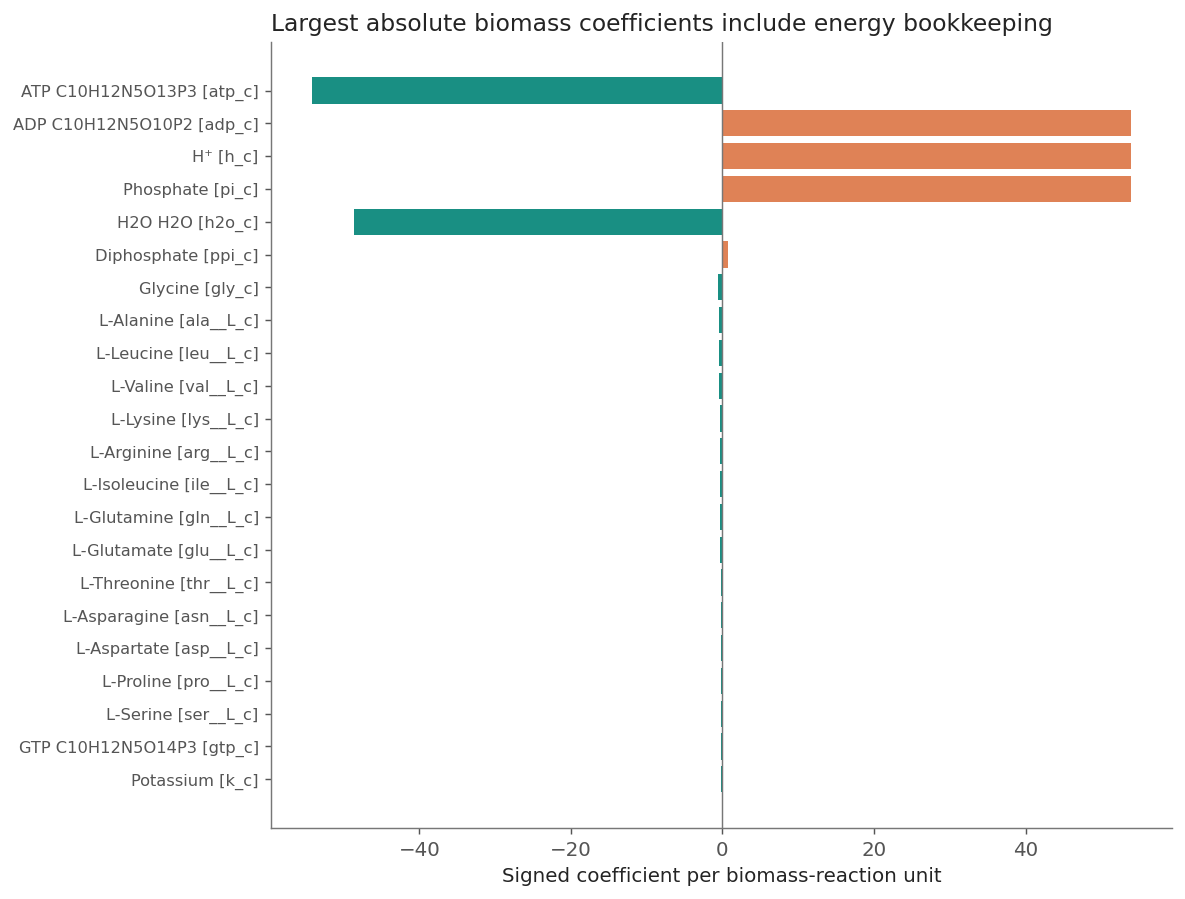

In [7]:
figures.biomass(biomass)
plt.show()

**Try a second view.** Remove the large energy-bookkeeping entries to inspect precursor demands. This changes only the table view. It does not change the biomass reaction or the optimization.

In [8]:
energy_bookkeeping = {'atp_c', 'adp_c', 'h2o_c', 'h_c', 'pi_c'}
display(biomass.query('coefficient < 0').loc[lambda t: ~t.id.isin(energy_bookkeeping)].head(20))

,id,name,coefficient,role,absolute_coefficient
6,gly_c,Glycine,-0.612638,consumed,0.612638
7,ala__L_c,L-Alanine,-0.513689,consumed,0.513689
8,leu__L_c,L-Leucine,-0.450531,consumed,0.450531
9,val__L_c,L-Valine,-0.423162,consumed,0.423162
10,lys__L_c,L-Lysine,-0.343161,consumed,0.343161
11,arg__L_c,L-Arginine,-0.295792,consumed,0.295792
12,ile__L_c,L-Isoleucine,-0.290529,consumed,0.290529
13,gln__L_c,L-Glutamine,-0.263160,consumed,0.263160
14,glu__L_c,L-Glutamate,-0.263160,consumed,0.263160
15,thr__L_c,L-Threonine,-0.253687,consumed,0.253687


### Weight the same biomass entries by molecular weight

Does the molar ranking also identify the largest mass contributions? For a coefficient $s_i$ in mmol/gDW and molecular weight $M_i$ in g/mol, the signed mass throughput is

$$m_i=\frac{s_iM_i}{1000}\quad\mathrm{g/gDW}.$$

The sign still matters. ATP is converted to ADP and phosphate while material is incorporated into biomass. Normalizing all consumed masses would count this turnover as cell material. Compare the complete signed balance before calling a quantity a composition fraction.

In [9]:
mass = pd.DataFrame([
    {'id':met.id, 'name':met.name, 'coefficient_mmol_gDW':coefficient,
     'molecular_weight_g_mol':met.formula_weight,
     'signed_mass_g_gDW':coefficient * met.formula_weight / 1000}
    for met, coefficient in biomass_reaction.metabolites.items()
])
mass['absolute_mass_g_gDW'] = mass.signed_mass_g_gDW.abs()
mass = mass.sort_values('absolute_mass_g_gDW', ascending=False)
display(mass.head(12))
consumed = -mass.loc[mass.signed_mass_g_gDW < 0, 'signed_mass_g_gDW'].sum()
produced = mass.loc[mass.signed_mass_g_gDW > 0, 'signed_mass_g_gDW'].sum()
print(f'Gross consumed: {consumed:.6f}; gross produced: {produced:.6f} g/gDW')
print(f'Net material retained: {consumed-produced:.6f} g/gDW')
assert abs(consumed-produced-1) < 1e-4
display(mass.set_index('id').loc[['gly_c','leu__L_c','kdo2lipid4_e','murein5px4p_p']])
mass.to_csv(HERE / 'data/biomass-mass-ranked.csv', index=False)

,id,name,coefficient_mmol_gDW,molecular_weight_g_mol,signed_mass_g_gDW,absolute_mass_g_gDW
10,atp_c,ATP C10H12N5O13P3,-54.124831,503.149263,-27.232869,27.232869
4,adp_c,ADP C10H12N5O10P2,53.950000,424.177302,22.884365,22.884365
55,pi_c,Phosphate,53.945662,95.979301,5.177667,5.177667
31,h2o_c,H2O H2O,-48.601527,18.015280,-0.875570,0.875570
56,ppi_c,Diphosphate,0.773903,174.951262,0.135395,0.135395
30,gtp_c,GTP C10H12N5O14P3,-0.215096,519.148663,-0.111667,0.111667
69,utp_c,UTP C9H11N2O15P3,-0.144104,480.109323,-0.069186,0.069186
17,ctp_c,CTP C9H12N3O14P3,-0.133508,479.124563,-0.063967,0.063967
37,leu__L_c,L-Leucine,-0.450531,131.172920,-0.059097,0.059097
32,h_c,H+,53.950000,1.007940,0.054378,0.054378


Gross consumed: 29.251801; gross produced: 28.251806 g/gDW
Net material retained: 0.999994 g/gDW


,name,coefficient_mmol_gDW,molecular_weight_g_mol,signed_mass_g_gDW,absolute_mass_g_gDW
id,,,,,
gly_c,Glycine,-0.612638,75.066600,-0.045989,0.045989
leu__L_c,L-Leucine,-0.450531,131.172920,-0.059097,0.059097
kdo2lipid4_e,KDO(2)-lipid IV(A),-0.019456,1840.012642,-0.035799,0.035799
murein5px4p_p,"Two disacharide linked murein units, pentapept...",-0.013894,1892.829380,-0.026299,0.026299


Leucine has fewer molecules in this column than glycine but contributes more mass. Lipids and cell-wall compounds also move upward in the ranking. The gross consumed and produced masses are both much larger than one gram. Their difference is approximately one gram per gram dry biomass.

**Change the table view:** set `exclude_turnover=False` below to see how ATP bookkeeping dominates the gross ranking. Excluding those entries improves visibility but does not by itself recover polymer composition.

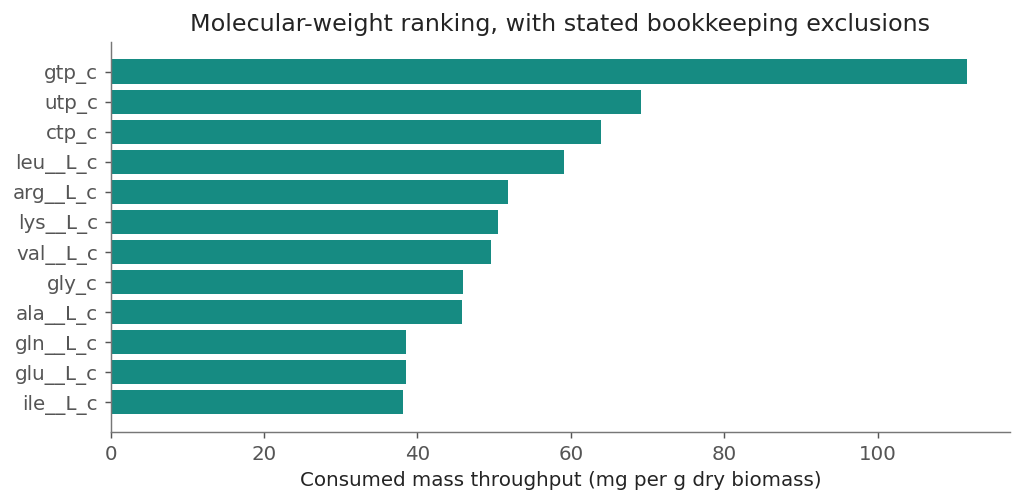

In [10]:
exclude_turnover = True
view = mass.loc[mass.signed_mass_g_gDW < 0].copy()
if exclude_turnover:
    view = view.loc[~view.id.isin({'atp_c','adp_c','h2o_c','h_c','pi_c','ppi_c'})]
view = view.head(12).sort_values('absolute_mass_g_gDW')
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(view.id, 1000 * view.absolute_mass_g_gDW, color='#168b82')
ax.set_xlabel('Consumed mass throughput (mg per g dry biomass)')
ax.set_title('Molecular-weight ranking, with stated bookkeeping exclusions')
fig.tight_layout()
plt.show()

## 3. Change one bound, solve, and restore it

An exchange reaction is negative when uptake is allowed in this model convention. A glucose lower bound of −10 allows uptake up to 10 mmol/(gDW·h). It does not force the cell to use all 10. We will compare oxygen availability while holding the glucose cap fixed. The `with model:` context restores the original state even if an experiment raises an exception.

In [11]:
oxygen = model.reactions.get_by_id('EX_o2_e')
print('Before the experiment:', oxygen.bounds)
with model:
    demo.set_medium(model, glucose=10, oxygen=20)
    aerobic = model.optimize()
    print('Aerobic maximum growth:', round(aerobic.objective_value, 4), '1/h')
    oxygen.lower_bound = 0.0  # one deliberate change: forbid oxygen uptake
    anaerobic = model.optimize()
    print('Anaerobic maximum growth:', round(anaerobic.objective_value, 4), '1/h')
    display(pd.DataFrame({'aerobic': aerobic.fluxes, 'anaerobic': anaerobic.fluxes})
            .loc[['EX_glc__D_e','EX_o2_e','EX_ac_e','EX_for_e','EX_etoh_e','ATPM']])
print('After the experiment:', oxygen.bounds)

Before the experiment: (-1000.0, 1000.0)
Aerobic maximum growth: 0.9824 1/h
Anaerobic maximum growth: 0.2415 1/h


,aerobic,anaerobic
EX_glc__D_e,-10.000000,-10.000000
EX_o2_e,-17.578934,0.000000
EX_ac_e,0.000000,8.207632
EX_for_e,0.000000,17.283320
EX_etoh_e,0.000000,8.077669
ATPM,3.150000,3.150000


After the experiment: (-1000.0, 1000.0)


The optimization predicts a lower growth bound without oxygen and a different exchange pattern. A particular optimal flux vector need not be unique. The growth optimum is the primary comparison here. We can explicitly ask for the range of a flux among equally optimal solutions.

In [12]:
from cobra.flux_analysis import flux_variability_analysis
with model:
    demo.set_medium(model, glucose=10, oxygen=20)
    display(flux_variability_analysis(model, reaction_list=['PFK','EX_ac_e'], fraction_of_optimum=1.0, processes=1))

,minimum,maximum
PFK,0.0,7.784186e+00
EX_ac_e,0.0,-9.759577e-13


## 4. Change the carbon source and watch feasibility

Growth on succinate uses a different set of redox and energy routes. Closing glucose uptake while opening succinate uptake is an interpretable change to the environment. The mandatory ATP-maintenance lower bound remains part of the reconstruction. An infeasible case means these combined requirements cannot all be met.

In [13]:
conditions = []
for name, glucose_cap, oxygen_cap, succinate_cap in [
    ('Glucose, aerobic', 10, 20, 0),
    ('Glucose, oxygen limited', 10, 5, 0),
    ('Glucose, anaerobic', 10, 0, 0),
    ('Succinate, aerobic', 0, 20, 20),
    ('Succinate, anaerobic', 0, 0, 20),
]:
    row = demo.solve_condition(model, glucose_cap, oxygen_cap, succinate_cap)
    row['condition'] = name
    conditions.append(row)
display(pd.DataFrame(conditions).set_index('condition').round(4))
print('Mandatory ATP-maintenance lower bound:', model.reactions.ATPM.lower_bound)

,glucose,oxygen,succinate,status,growth,EX_glc__D_e,EX_o2_e,EX_ac_e,EX_co2_e,ATPM
condition,,,,,,,,,,
"Glucose, aerobic",10,20,0,optimal,0.9824,-10.0,-17.5789,0.0000,19.6752,3.15
"Glucose, oxygen limited",10,5,0,optimal,0.4915,-10.0,-5.0000,11.3519,-0.0166,3.15
"Glucose, anaerobic",10,0,0,optimal,0.2415,-10.0,0.0000,8.2076,-0.0882,3.15
"Succinate, aerobic",0,20,20,optimal,0.7774,0.0,-20.0000,8.2130,31.6602,3.15
"Succinate, anaerobic",0,0,20,infeasible,NaN,NaN,NaN,NaN,NaN,NaN


Mandatory ATP-maintenance lower bound: 3.15


**Change one number live.** Increase the glucose cap from 5 to 10 while keeping oxygen at 5. Then try oxygen at 20. The function restores every bound after each call, so the order of experiments does not affect the result.

In [14]:
display(pd.DataFrame([demo.solve_condition(model, glucose=g, oxygen=o)
                      for o in [5,20] for g in [5,10]])[['glucose','oxygen','growth']].round(4))

,glucose,oxygen,growth
0,5,5,0.3387
1,10,5,0.4915
2,5,20,0.4847
3,10,20,0.9824


## 5. Dynamic FBA: let the culture consume its environment

In a batch culture, extracellular glucose changes. At every ODE evaluation we solve a new intracellular FBA problem. With biomass concentration $X$ and external glucose $G$,

$$\dot X=\mu^*(G)X,\qquad \dot G=v^*_{\rm EX,glucose}(G)X,$$
$$-v_{\rm EX,glucose}\leq 10\frac{G}{0.5+G}.$$

The small archived E. coli core model makes this calculation fast. Here $X$ is gDW/L, $G$ is mmol/L and time is hours. Oxygen uptake is capped at 20 mmol/(gDW·h). **For this depletion demonstration only, ATP maintenance is set to zero.** This isolates resource-limited growth and permits a no-growth endpoint. Keeping mandatory maintenance would require a separate starvation or feasibility rule.

Internal metabolites still satisfy $Sv=0$ at every solve. The new state memory is in the external resource and population. This is the dynamic-FBA idea of Mahadevan, Edwards and Doyle (2002), illustrated with a new numerical setup.

Glucose threshold reached at: 4.099 h
Final biomass: 0.9666 gDW/L


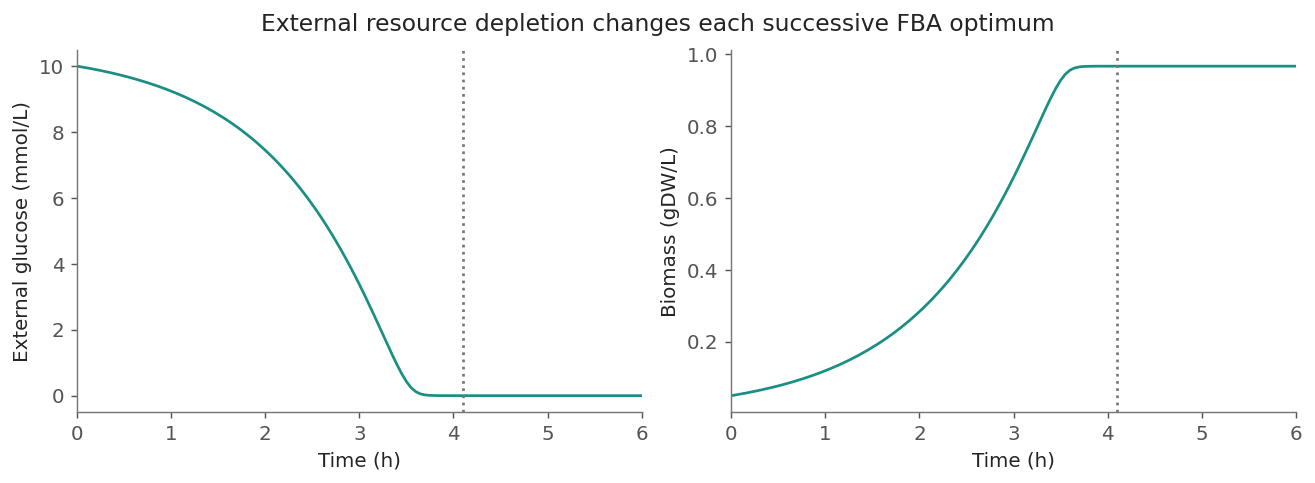

In [15]:
batch = demo.batch_dfba(initial_biomass=0.05, initial_glucose=10, km=0.5)
print('Glucose threshold reached at:', round(batch['stop_time'],3), 'h')
print('Final biomass:', round(batch['biomass'][-1],4), 'gDW/L')
figures.batch(batch)
plt.show()

**Experiment:** double the initial biomass. This changes the speed of resource consumption. It does not change the intracellular objective. Compare the depletion time and final biomass.

In [16]:
denser_batch = demo.batch_dfba(initial_biomass=0.10, initial_glucose=10)
display(pd.DataFrame([
    {'initial biomass':0.05, 'depletion time':batch['stop_time'], 'final biomass':batch['biomass'][-1]},
    {'initial biomass':0.10, 'depletion time':denser_batch['stop_time'], 'final biomass':denser_batch['biomass'][-1]},
]).round(4))

,initial biomass,depletion time,final biomass
0,0.05,4.0989,0.9666
1,0.10,3.3235,1.0166


## 6. Add a community environment

The supplied ecology module uses the same pattern as batch dFBA: solve per-species metabolic problems, then integrate biomasses and extracellular resources. Its primary mechanism follows the carbon/oxygen interaction in Khazaei et al. (2020). Their experiment used continuous culture. Serial dilution is a separate, explicitly constructed protocol in this teaching package.

Species B degrades polymer and releases simple carbon. Species A consumes simple carbon and oxygen. That oxygen removal helps the anaerobic species B. Each species maximizes its own instantaneous growth subject to its small metabolic LP. Both species and all three external resources are dynamic. The organisms, coefficients and curves here are a new illustrative reduction, not a reproduction of the paper's whole-genome models.

In [17]:
from ecology.ecology_dfba import (EcologyParameters, solve_fluxes, simulate_cstr,
                                 simulate_serial_dilution, hysteresis_sweep)
ecology_parameters = EcologyParameters()
flux_example = solve_fluxes([0.5,10.0,0.2], ecology_parameters)  # actual HiGHS LPs
print('Growth rates at these external resources:', flux_example['growth_rate'])
print('Species A LP fluxes:', flux_example['facultative_fluxes'])
print('Species B LP fluxes:', flux_example['anaerobe_fluxes'])

Growth rates at these external resources: [9.09090909e-01 1.20236160e-04]
Species A LP fluxes: [18.18181818 18.18181818 18.18181818  0.          0.90909091]
Species B LP fluxes: [0.00601181 0.00601181 0.0030059  0.00012024]


**Run two inoculation histories under the same continuous feed.** The dilution rate is 0.1 h⁻¹. The medium supplies 0.5 mmol/L simple carbon and 10 mmol/L polymer-equivalent carbon, with oxygen transfer toward 0.2 mmol/L. The histories differ in initial biomass and oxygen. Actual LPs are solved during both trajectories. One history approaches a state with negligible B. The other sustains both species by lowering oxygen.

,history,final A,final B,final oxygen,steady residual
0,Initially oxygenated,0.024722,0.000000,0.150556,0.0
1,Initially established anaerobe,0.134263,0.198571,0.000632,0.0


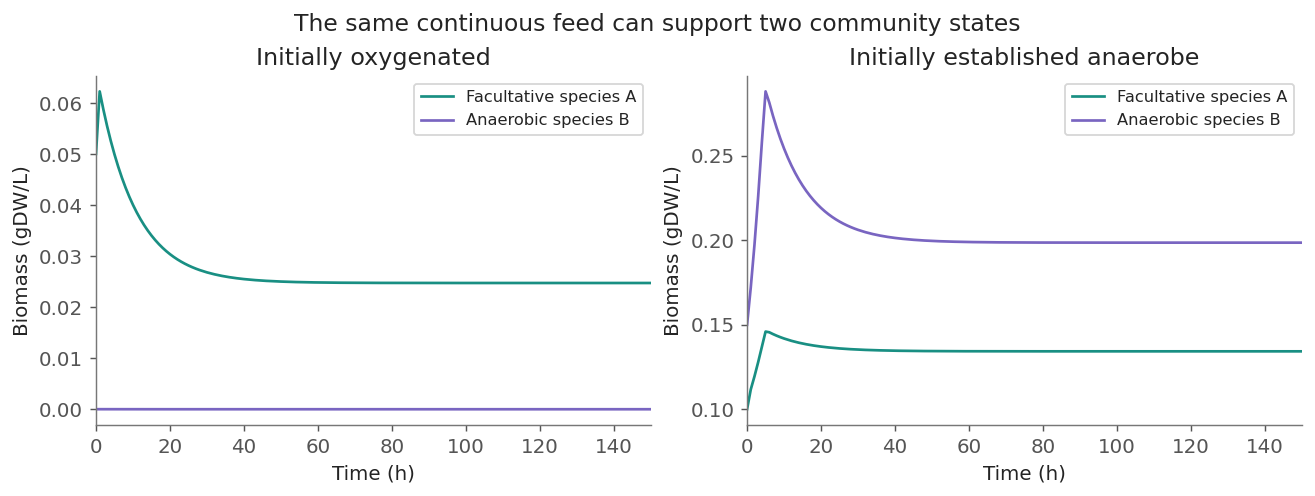

In [18]:
cstr = {
    'Initially oxygenated': simulate_cstr([.05,1e-5,.5,10,.2],backend='lp'),
    'Initially established anaerobe': simulate_cstr([.1,.15,.5,10,.001],backend='lp'),
}
display(pd.DataFrame([{'history':name,'final A':d['biomass'][-1,0],
                      'final B':d['biomass'][-1,1],'final oxygen':d['resources'][-1,2],
                      'steady residual':np.max(np.abs(d['terminal_derivative']))}
                     for name,d in cstr.items()]).round(7))
figures.ecology_cstr(cstr)
plt.show()

**Draw the exchange mechanism before interpreting the trajectories.** Polymer breakdown supplies simple carbon. Oxygen consumption changes the environment experienced by the anaerobe. This feedback can support different community states under the same feed.

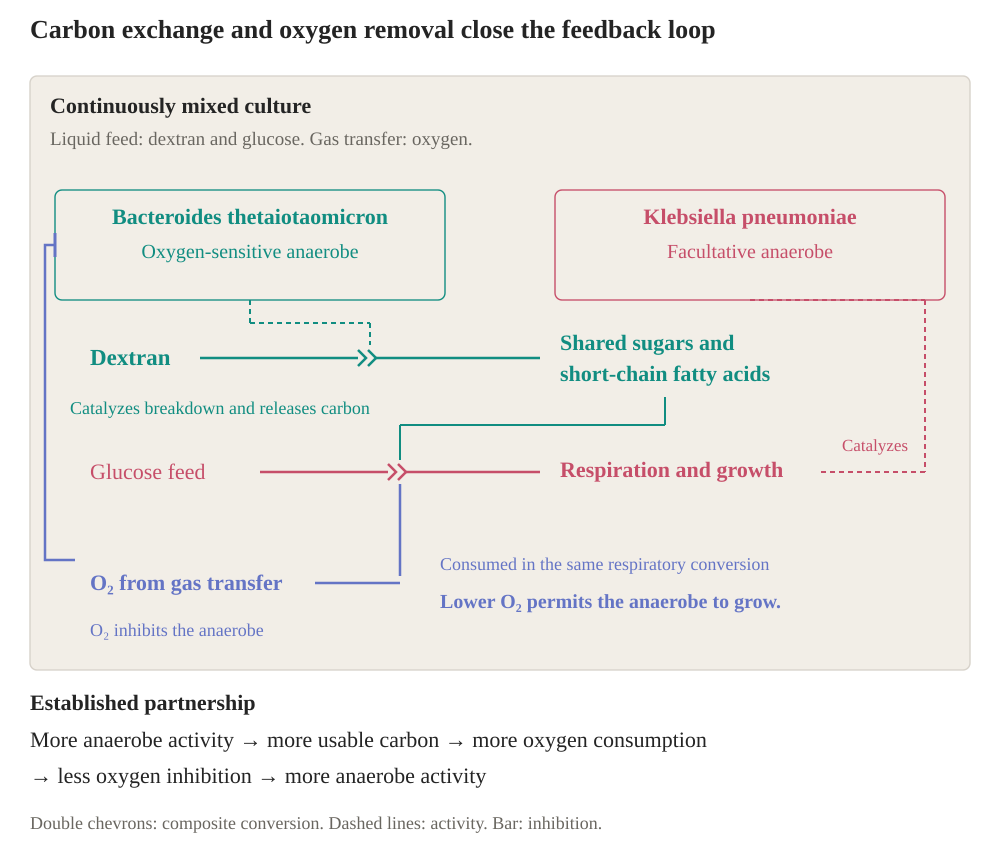

In [19]:
display(SVG(filename=str(HERE / 'figures/community-mechanism.svg')))

**Sweep a parameter in both directions.** Begin each new oxygen-supply condition from the previous final state. At the start of each condition, a rare-species probe of $10^{-8}$ gDW/L tests whether a missing species can invade. This avoids making numerical extinction an irreversible rule. The probes are not continuous immigration.

Each step runs for 1,000 hours to approach its attractor. The two curves therefore compare slowly changed conditions, not the lag from a fast ramp. Different switching thresholds expose the two branches of the model's hysteresis.

Largest final derivative: 3.750608851271764e-11


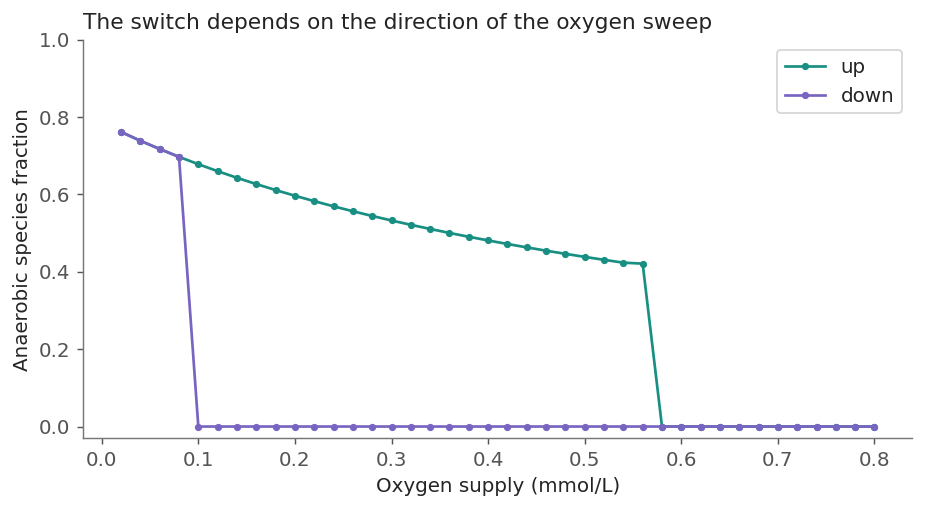

In [20]:
oxygen_supply = np.linspace(.02,.8,40)
hysteresis = {direction:hysteresis_sweep(oxygen_supply,direction=direction,backend='analytic',
                                       duration_per_step=1000.) for direction in ['up','down']}
print('Largest final derivative:', max(np.max(d['derivative_error']) for d in hysteresis.values()))
figures.ecology_hysteresis(hysteresis)
plt.show()

## 7. Choose the culture protocol before predicting the winner

A continuous culture maintains inflow and outflow. A serial culture alternates growth with an abrupt transfer. A batch culture has neither replacement during growth nor a repeating long-term environment. The averaging convention must be stated when comparing them.

Take two unit-yield consumers with $\mu_i(R)=V_iR/(K_i+R)$. Consumer A has a lower half-saturation constant. Consumer B grows faster at abundant resource. Keep the same feed and match logarithmic cell loss:

$$D=0.15\ {\rm h}^{-1},\qquad f=0.01,\qquad T=-\log(f)/D.$$

This matches cell dilution over a cycle. It does not match fresh-medium volume per hour. The reduced model solves the uptake-limited single-route LP analytically. Its kinetics and parameters are declared teaching choices.

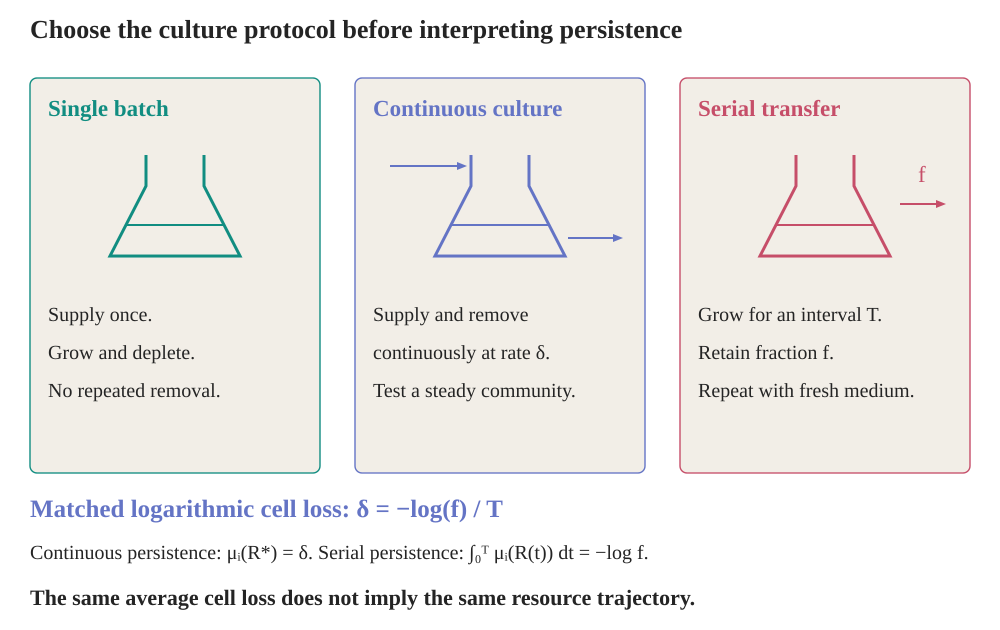

Growth capacities: [0.6 1.2]
Half-saturation constants: [0.05 0.4 ]
Transfer interval: 30.701134573253942 h


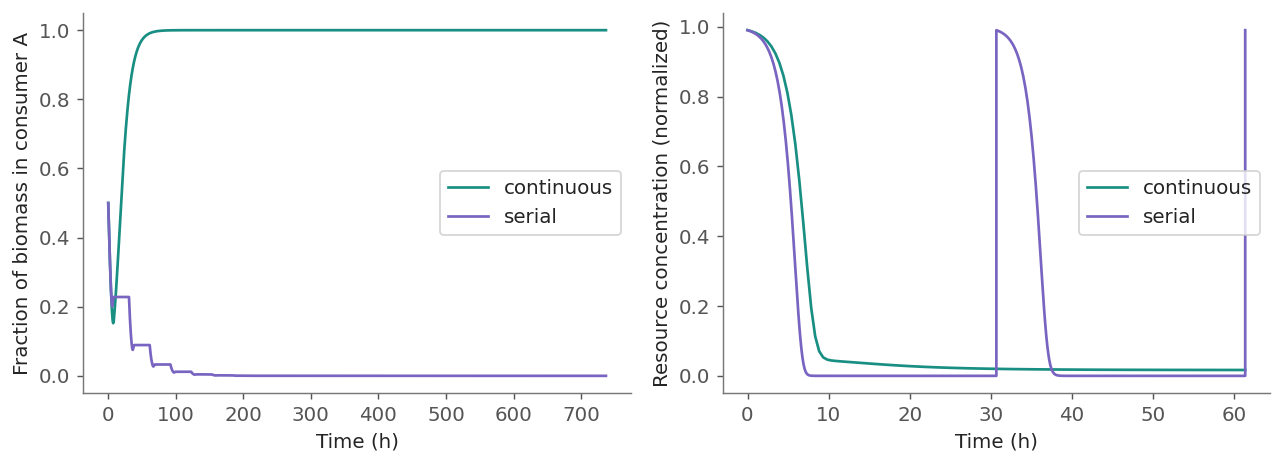

,protocol,final fraction A
0,continuous,1.000000e+00
1,serial,1.371423e-11


Continuous invasion rates: {'break_even_resource': [0.016666666666666666, 0.05714285714285714], 'B_into_A': -0.102, 'A_into_B': 0.16999999999999996}


,resident,invader,resource_start,resource_end,log_multiplier,multiplier
0,0,1,0.99,9.900000e-119,1.679788,5.364418
1,1,0,0.99,9.900000e-34,-1.029231,0.357282


In [21]:
display(SVG(filename=str(HERE / 'figures/culture-protocols.svg')))
print('Growth capacities:', culture_protocol.V)
print('Half-saturation constants:', culture_protocol.K)
print('Transfer interval:', culture_protocol.INTERVAL, 'h')
protocol_runs = {name:culture_protocol.simulate(name)
                 for name in ['continuous','serial']}
fig, axes = plt.subplots(1,2,figsize=(10,3.7))
for name, result in protocol_runs.items():
    axes[0].plot(result['time'], result['fraction_A'], label=name)
    mask = result['time'] <= 2*culture_protocol.INTERVAL
    axes[1].plot(result['time'][mask], result['resource'][mask], label=name)
axes[0].set(xlabel='Time (h)', ylabel='Fraction of biomass in consumer A')
axes[1].set(xlabel='Time (h)', ylabel='Resource concentration (normalized)')
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame([{'protocol':name, 'final fraction A':r['fraction_A'][-1]}
                      for name,r in protocol_runs.items()]))
print('Continuous invasion rates:', culture_protocol.continuous_invasion())
display(pd.DataFrame([culture_protocol.resident_cycle(i) for i in [0,1]]))

A wins in continuous culture. B wins in serial culture. The rare-invader calculations check that this difference is not just a slow transient. This example changes membership, not the number of surviving species.

**Try shorter transfers:** change the retained fraction while recomputing the interval to hold `D` fixed. Reading the invader multiplier is faster than repeatedly simulating many cycles. A multiplier greater than one means the rare consumer increases over a complete resident cycle.

In [22]:
old_retention, old_interval = culture_protocol.RETENTION, culture_protocol.INTERVAL
try:
    rows = []
    for retention in [.01,.1,.5,.9]:
        culture_protocol.RETENTION = retention
        culture_protocol.INTERVAL = -np.log(retention)/culture_protocol.DILUTION
        rows.append({'retained fraction':retention,
                     'interval h':culture_protocol.INTERVAL,
                     'B into A multiplier':culture_protocol.resident_cycle(0)['multiplier'],
                     'A into B multiplier':culture_protocol.resident_cycle(1)['multiplier']})
    display(pd.DataFrame(rows))
finally:
    culture_protocol.RETENTION, culture_protocol.INTERVAL = old_retention, old_interval

,retained fraction,interval h,B into A multiplier,A into B multiplier
0,0.01,30.701135,5.364418,0.357282
1,0.10,15.350567,1.754116,0.758215
2,0.50,4.620981,0.942809,1.183626
3,0.90,0.702403,0.942875,1.115707


### Return to the carbon–oxygen community under repeated transfer

**Now change the experimental protocol.** After each 12-hour batch, keep 30% of the culture and replenish the rest with fresh medium. These are newly chosen teaching parameters. Plot the state immediately after each transfer. This tests convergence to a repeatable cycle, rather than a constant continuous-culture state.

For the longer repeated simulations, `backend='analytic'` evaluates the exact optimizer of these particular tiny LPs. Its equality to HiGHS has been independently checked across resource conditions. The mathematical model is unchanged. Change it to `'lp'` to resolve the LP at every ODE evaluation.

,history,final A after transfer,final B after transfer,last-cycle change
0,Small anaerobic inoculum,0.007500,5.253848e-37,2.775558e-17
1,Established anaerobe,0.038629,5.999975e-02,2.385270e-09


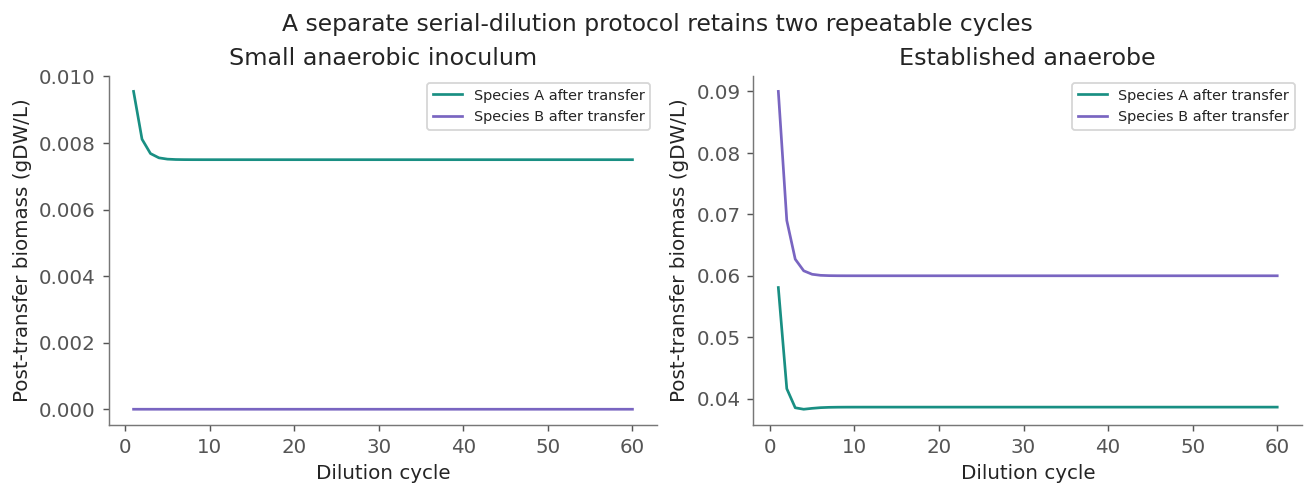

In [23]:
from ecology.ecology_dfba import simulate_serial_dilution
serial = {
    'Small anaerobic inoculum': simulate_serial_dilution([.01,1e-7,.5,10,.2],cycles=60,backend='analytic'),
    'Established anaerobe': simulate_serial_dilution([.1,.1,.5,10,.001],cycles=60,backend='analytic'),
}
display(pd.DataFrame([{'history':name,'final A after transfer':d['post_dilution'][-1,0],
                      'final B after transfer':d['post_dilution'][-1,1],
                      'last-cycle change':d['convergence_error']} for name,d in serial.items()]))
figures.ecology_serial(serial)
plt.show()

## 8. Proteome allocation: why use a lower-yield pathway?

High carbon yield need not mean low protein cost. A simple reduction makes this tradeoff visible. Let $u$ be substrate processing, $r$ respiration, $f$ fermentation and $\mu$ growth. Use

$$u=r+f,\qquad \mu=0.4r+0.2f,\qquad
0.12r+0.03f+0.5\mu\leq0.5.$$

Maximize $\mu$ subject to the uptake cap and nonnegative fluxes. The last inequality is a protein budget. The flux normalization makes its terms dimensionless protein fractions. The coefficients are illustrative, not an E. coli fit. The mechanism follows allocation models such as Basan et al. (2015) and constrained allocation FBA.

At low uptake, respiration gives more growth from each unit of substrate. Its total protein cost is $0.12+0.5(0.4)=0.32$ per unit of respiratory flux. The all-respiration solution reaches the budget at $u=0.5/0.32=1.5625$. Further growth requires the cheaper fermentative route.

Predicted overflow threshold: 1.5625


,capacity,respiration,fermentation,growth,protein
0,1.0,1.0000,0.0000,0.4000,0.32
1,2.0,1.2632,0.7368,0.6526,0.50
2,4.0,0.0000,3.8462,0.7692,0.50


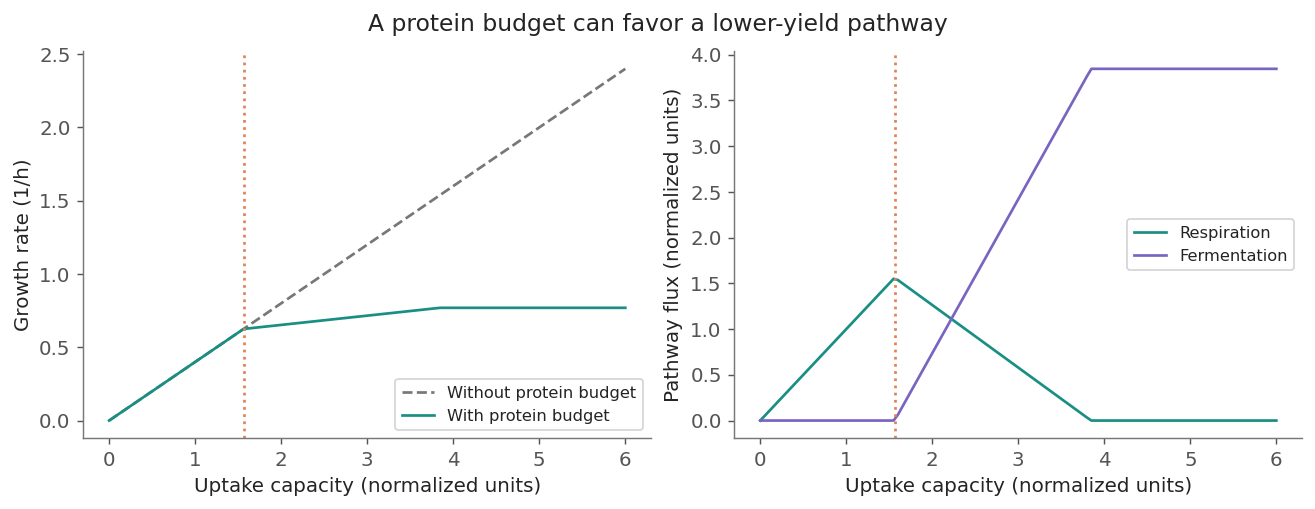

In [24]:
protein = demo.proteome_sweep()
print('Predicted overflow threshold:', protein['overflow_threshold'])
display(pd.DataFrame([demo.proteome_fluxes(cap) for cap in [1.0,2.0,4.0]])
        [['capacity','respiration','fermentation','growth','protein']].round(4))
figures.proteome(protein)
plt.show()

**Experiment:** change the protein budget while holding uptake capacity at 2. A larger budget can restore the higher-yield route. The result changes because a physiological resource was added to the constraints.

In [25]:
display(pd.DataFrame([demo.proteome_fluxes(2.0, protein_budget=p) for p in [0.4,0.5,0.8]])
        [['budget','respiration','fermentation','growth']].round(4))

,budget,respiration,fermentation,growth
0,0.4,0.7368,1.2632,0.5474
1,0.5,1.2632,0.7368,0.6526
2,0.8,2.0000,0.0000,0.8000


## 9. Proteome reserve: an upshift needs an allocation state

A static protein budget does not determine how fast ribosomes accumulate. Mori et al. (2017), Eqs. (2)–(8), retain ribosomal protein mass $M_R$ and total protein mass $M$. With ribosome fraction $\phi_R=M_R/M$ and allocation fraction $\chi_R$,

$$\dot M=\sigma\phi_R M,\qquad
\dot\phi_R=\sigma\phi_R(\chi_R-\phi_R),\qquad \mu=\sigma\phi_R.$$

For an upshift to rich medium, the paper approximates $\sigma$ and $\chi_R$ as jumping immediately to their final constants. The internal state that relaxes is $\phi_R$, not $\sigma$. Set final $\mu_f=2.45$ h⁻¹ and $\phi_R^f=0.50$, the paper's reported scales. The three initial fractions below are chosen illustrations. The exact solution is

$$\mu(t)=\frac{\mu_f}{1+(\mu_f/\mu_0-1)e^{-\mu_ft}},\qquad
\frac{M(t)}{M(0)}=1+\frac{\mu_0}{\mu_f}(e^{\mu_ft}-1),\qquad
\mu_0=\phi_R^i\frac{\mu_f}{\phi_R^f}.$$

The assumption that metabolic precursors become nonlimiting is central. The paper explicitly leaves biosynthetically limited downshifts to incomplete medium outside this simple model. This is a dynamic allocation model related to the same physiology, not a claim that static FBA alone generates the recovery.

,initial ribosome fraction,growth immediately after upshift,final growth
0,0.03,0.147,2.45
1,0.10,0.490,2.45
2,0.20,0.980,2.45


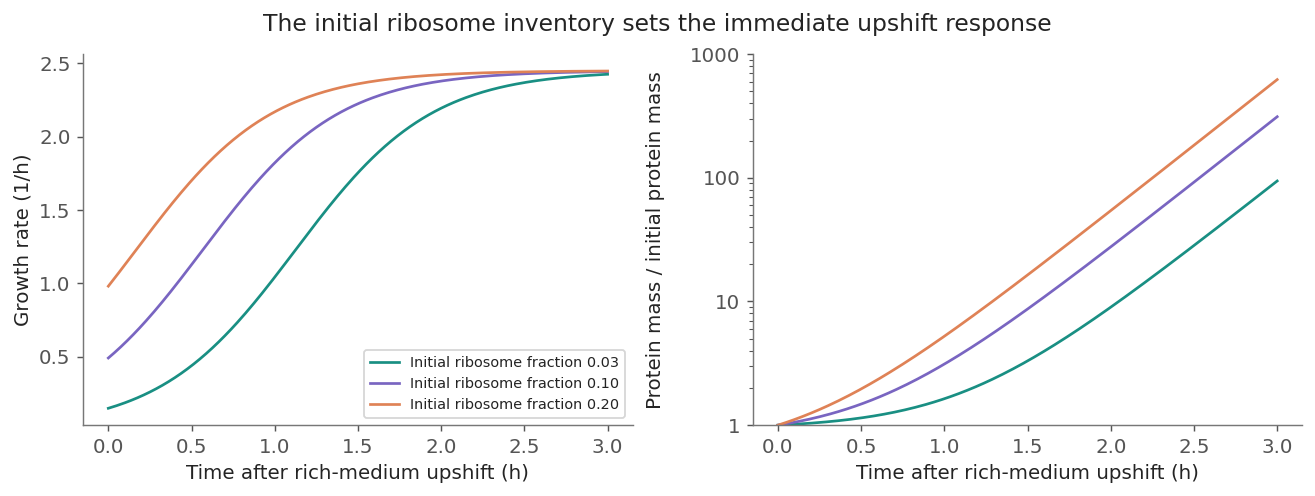

In [26]:
upshifts = [demo.mori_upshift(phi_initial=p) for p in [0.03,0.10,0.20]]
display(pd.DataFrame([{'initial ribosome fraction':d['phi_initial'],
                      'growth immediately after upshift':d['growth_initial_after_shift'],
                      'final growth':d['growth_final']} for d in upshifts]))
figures.mori(upshifts)
plt.show()

**Reserve has a cost as well as a benefit.** For a new reduction based on the paper's Eqs. (8) and (10), take a near-starved initial ribosome fraction equal to reserve $\phi_0$. Set $\phi_R^{\max}=0.48$, $\nu_R=6$ h⁻¹ and final growth $\mu_f=\nu_R(\phi_R^{\max}-\phi_0)$. These values approximate the paper's parameter scales. The resulting curves are a calculation from the equations, not traced experimental curves. More reserve gives a faster start while reducing the eventual growth rate. The preferred reserve depends on the duration of the feast.

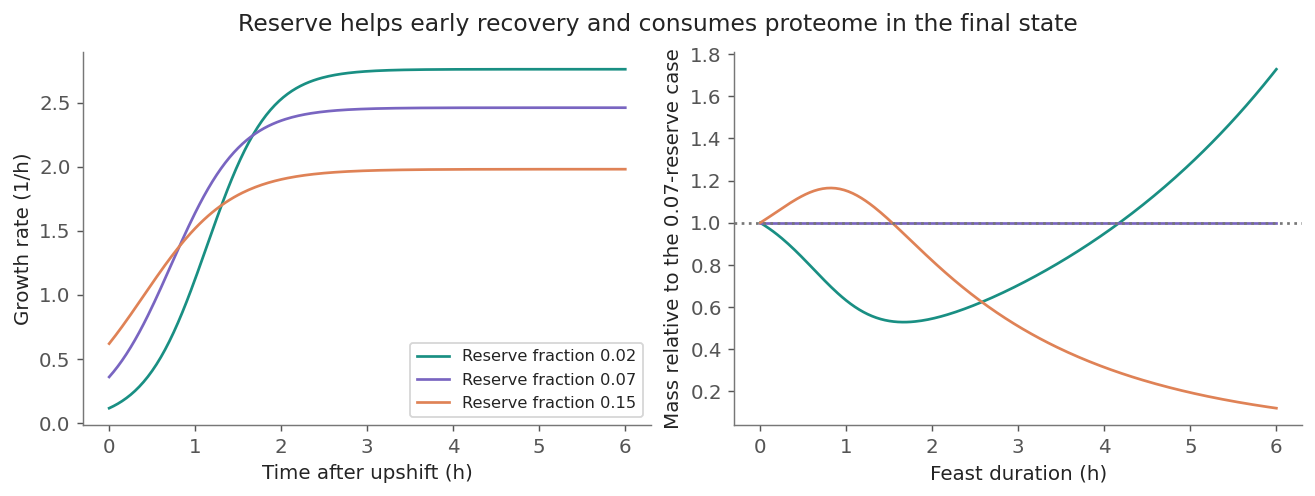

,reserve,mass after 0.5h,mass after 3h,mass after 6h
0,0.02,1.124,165.300,648195.513
1,0.07,1.353,234.711,375011.292
2,0.15,1.529,119.417,45110.235


In [27]:
reserve_curves = demo.reserve_comparison()
figures.reserves(reserve_curves)
plt.show()
display(pd.DataFrame([{'reserve':d['reserve'], 'mass after 0.5h':np.interp(.5,d['t'],d['mass']),
                      'mass after 3h':np.interp(3,d['t'],d['mass']),
                      'mass after 6h':d['mass'][-1]} for d in reserve_curves]).round(3))

### A distinct carbon-shift model retains translational activity

Erickson et al. (2017), Eq. (5), supplies the related one-dimensional equation for translational activity $\sigma$. It differs from Mori's rich-medium approximation:

$$\dot\sigma=\sigma[\mu_f\widehat\chi_{\rm Cat}(\sigma)-\sigma\widehat\chi_{\rm Rb}(\sigma)],$$
$$\widehat\chi_{\rm Rb}=\frac{\phi_{\rm Rb,0}}{1-\sigma/\gamma},\qquad
\widehat\chi_{\rm Cat}=\max\left(0,1-\frac{\sigma\widehat\chi_{\rm Rb}}{\lambda_C}\right),\qquad
\mu_f=\frac{\lambda_f}{1-\lambda_f/\lambda_C}.$$

Here $\mu_f$ parameterizes post-shift carbon uptake capacity. It is not the instantaneous growth rate, which is $\lambda=\sigma\phi_{\rm Rb}$. The ribosome fraction obeys $\dot\phi_{\rm Rb}=\lambda(\widehat\chi_{\rm Rb}-\phi_{\rm Rb})$. Use the paper's fitted scales $\phi_{\rm Rb,0}=0.049$, $\gamma=11.02$ h⁻¹ and $\lambda_C=1.17$ h⁻¹. The particular growth conditions below are illustrative.

For an upshift without pre-expression of the new uptake system, $\sigma$ starts continuously at its old value. For removal of one co-utilized substrate, it initially drops by the ratio $\mu_f/\mu_i$ (SI Eqs. S52 and S56). This creates different recovery curves from the same allocation rule. The shaded first ten minutes identify a regime this coarse description does not resolve. The paper also excludes prolonged growth arrest.

,shift,growth before,growth immediately after,growth after 12 h,final steady growth
0,upshift,0.3,0.3000,0.8,0.8
1,downshift,0.8,0.1922,0.4,0.4


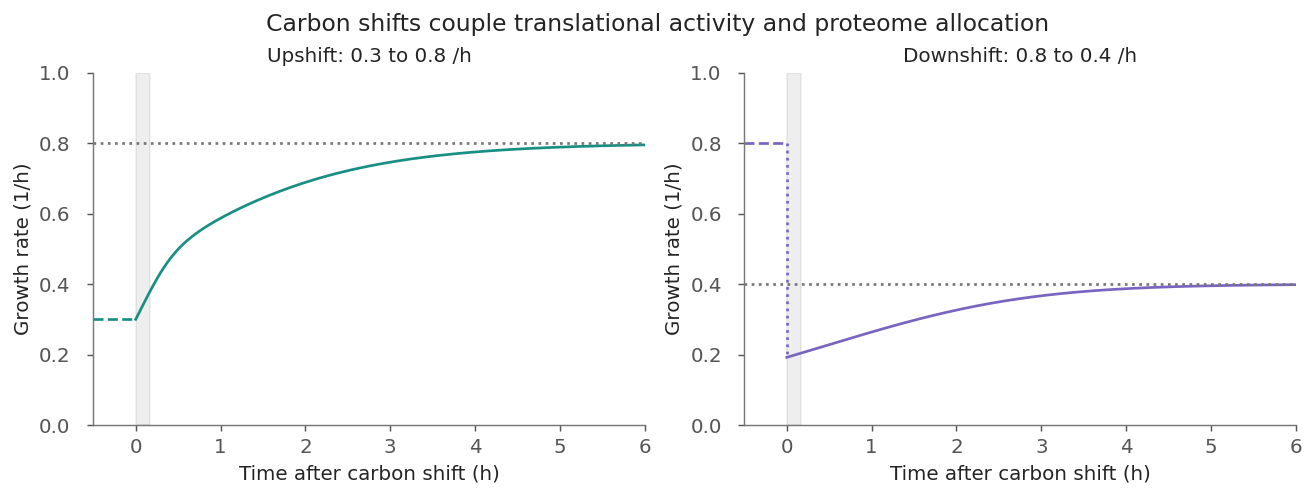

In [28]:
carbon_shifts = [demo.erickson_shift(kind=k) for k in ['upshift','downshift']]
display(pd.DataFrame([{'shift':d['kind'],'growth before':d['growth_before'],
                      'growth immediately after':d['growth'][0],
                      'growth after 12 h':d['growth'][-1],
                      'final steady growth':d['growth_final']} for d in carbon_shifts]).round(4))
figures.erickson(carbon_shifts)
plt.show()

## 10. Test a real coupled reaction with chemical potentials

ATP coupling can favor a reaction without removing its thermodynamic condition. For hexokinase,

$$\mathrm{glucose+ATP}\rightsquigarrow\mathrm{glucose\ 6\!-\!phosphate+ADP},$$
$$\Delta G=\Delta G^{\circ\prime}+RT\log
\frac{a_{\rm G6P}a_{\rm ADP}}{a_{\rm glucose}a_{\rm ATP}}.$$

Greinert et al. (2021), Table 1, gives $\Delta G^{\circ\prime}=-17.8\pm0.5$ kJ/mol at 298.15 K and pH 7. Activities are dimensionless. We choose $a_{\rm G6P}/a_{\rm glucose}=10$ and compare two declared ATP/ADP activity ratios. These are a subsystem feasibility test, not measured cellular states.

The LP balances glucose, ATP, glucose 6-phosphate and ADP with boundary exchanges. Ordinary FBA allows forward flux up to 10 in both conditions. The thermodynamic condition closes that direction when its reaction free energy is positive.

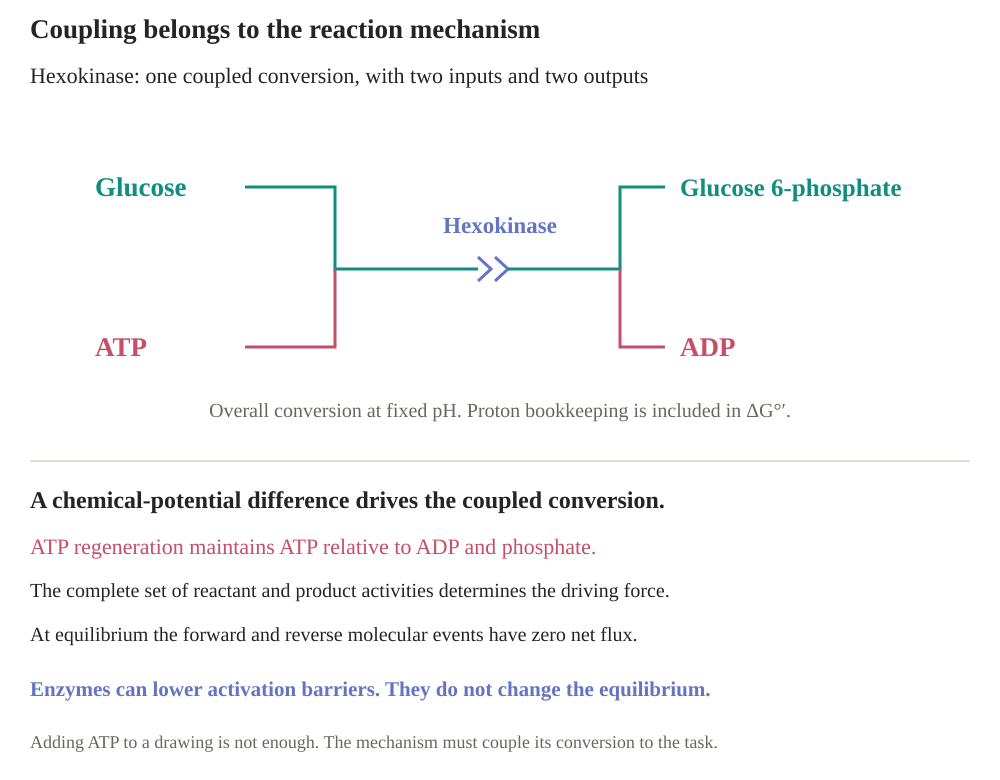

,atp_adp_ratio,energy,thermodynamic,output
0,1.000,-12.091990,False,10.0
1,1.000,-12.091990,True,10.0
2,0.001,5.032038,False,10.0
3,0.001,5.032038,True,-0.0


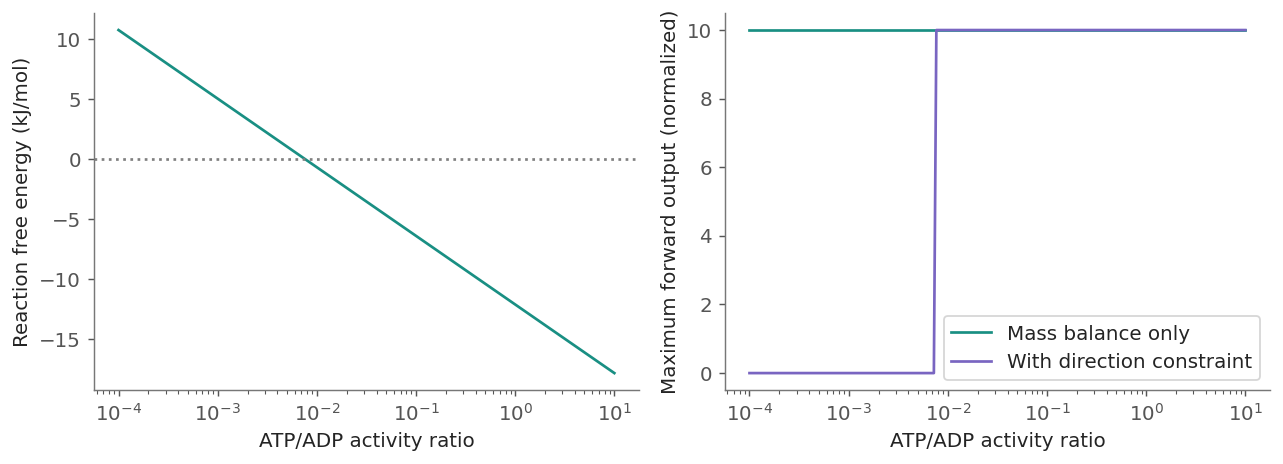

In [29]:
display(SVG(filename=str(HERE / 'figures/hexokinase-coupling.svg')))
energy_cases = [thermodynamics.optimize(ratio, thermodynamic=flag)
                for ratio in [1.,.001] for flag in [False,True]]
display(pd.DataFrame(energy_cases)[['atp_adp_ratio','energy','thermodynamic','output']])
ratios = np.logspace(-4,1,200)
fig, axes = plt.subplots(1,2,figsize=(10,3.7))
axes[0].semilogx(ratios, thermodynamics.reaction_energy(ratios))
axes[0].axhline(0,color='gray',linestyle=':')
axes[0].set(xlabel='ATP/ADP activity ratio',ylabel='Reaction free energy (kJ/mol)')
axes[1].semilogx(ratios, np.full_like(ratios,10),label='Mass balance only')
axes[1].semilogx(ratios, np.where(thermodynamics.reaction_energy(ratios)<0,10,0),
                 label='With direction constraint')
axes[1].set(xlabel='ATP/ADP activity ratio',ylabel='Maximum forward output (normalized)')
axes[1].legend()
fig.tight_layout()
plt.show()

**Change the chemical state:** evaluate `thermodynamics.reaction_energy(.01)` and then `.001`. A tenfold ATP/ADP change shifts this reaction energy by about 5.71 kJ/mol.

ATP hydrolysis also obeys $\Delta G=\Delta G^{\circ\prime}+RT\log(a_{\rm ADP}a_{\rm Pi}/a_{\rm ATP})$ under a fixed transformed standard state. Usable free energy is a property of the complete conversion and the chemical state. Breaking a bond by itself costs energy. Product formation and concentrations determine the net result. Favorable free energy permits a direction but does not establish its speed.

## 11. Thermodynamic constraints: exclude ATP from a closed cycle

Mass balance alone can permit an energetically impossible circulation. Consider an illustrative network with these composite conversions:

$$A+ADP\rightsquigarrow B+ATP,\qquad B\rightsquigarrow A.$$

Add an ATP drain, and optionally a legitimate fuel-coupled ATP source capped at 2. The two internal reactions can circulate at flux 10 in ordinary FBA. Their net effect is ADP-to-ATP conversion without consuming a net resource.

Phosphate, water and H⁺ are omitted chemostatted species in these transformed reactions. Their fixed chemical potentials are included in the stated ATP-synthesis free energy. The legitimate source additionally consumes supplied fuel and exports waste.

Let $d=\mu_B-\mu_A$ be the chemical-potential difference in kJ/mol and let ATP synthesis cost 30 kJ/mol in the selected state. The reaction free energies are $\Delta G_1=d+30$ and $\Delta G_2=-d$. Both active directions would require $\Delta G\leq-1$. Adding those inequalities demands $30\leq-2$, which is impossible. The legitimate fuel reaction has $\Delta G=-10$ and remains allowed.

The helper enumerates all four on/off patterns and solves the chemical-potential and flux feasibility problems. In a large network this direction/flux coupling is usually formulated with integer variables. The example concerns thermodynamic consistency, not simply preferring a smaller flux norm.

,condition,maximum ATP drain
0,no_fuel_fba,10.0
1,no_fuel_thermo,-0.0
2,fuel_fba,12.0
3,fuel_thermo,2.0


,active,potential_feasible,ATP,flux
0,"[0, 0]",True,2.0,"[0.0, 0.0, 2.0, 2.0]"
1,"[0, 1]",True,2.0,"[0.0, -0.0, 2.0, 2.0]"
2,"[1, 0]",True,2.0,"[-0.0, 0.0, 2.0, 2.0]"
3,"[1, 1]",False,NaN,NaN


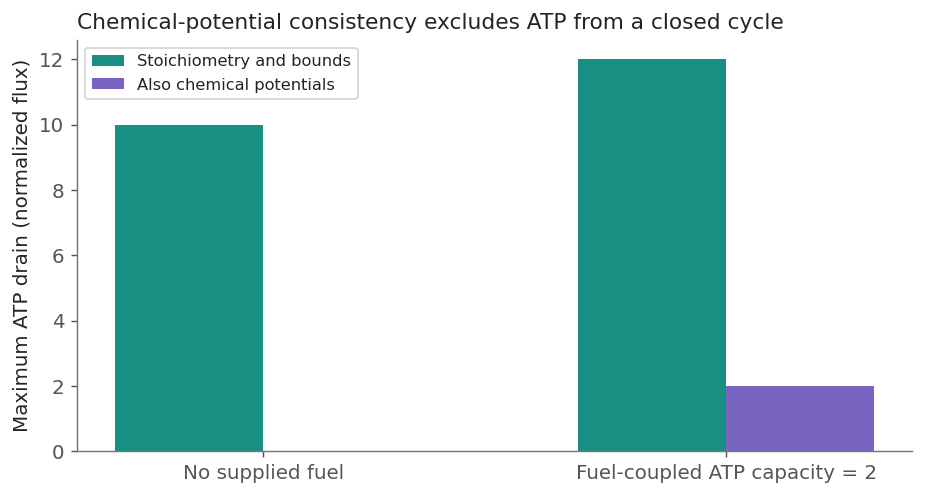

In [30]:
thermo = {name:demo.thermodynamic_cycle(fuel,flag) for name,fuel,flag in [
    ('no_fuel_fba',0,False), ('no_fuel_thermo',0,True),
    ('fuel_fba',2,False), ('fuel_thermo',2,True),
]}
display(pd.DataFrame([{'condition':name,'maximum ATP drain':d['ATP']} for name,d in thermo.items()]))
display(pd.DataFrame(thermo['fuel_thermo']['audits']))
figures.thermodynamics(thermo)
plt.show()

## 12. Enzyme constraints and kinetic saturation answer different questions

Two parallel enzymes convert the same substrate pool to a product that can enter a biomass drain. Stoichiometry alone gives product flux 10, set by uptake. Enzyme amounts add individual capacities:

$$v_i\leq k_{{\rm cat},i}E_i.$$

Choose normalized turnover constants $\begin{bmatrix}10&5\end{bmatrix}$ and enzyme amounts $\begin{bmatrix}0.6&0.4\end{bmatrix}$. The total maximum falls to $6+2=8$. If the substrate pool is only $q=0.1$, saturation adds another restriction:

$$v_i\leq k_{{\rm cat},i}E_i\frac{q}{K_i+q},\qquad \begin{bmatrix}K_1&K_2\end{bmatrix}=\begin{bmatrix}1&0.05\end{bmatrix}.$$

All values here are illustrative and use consistent normalized units. $E_i$ is an enzyme abundance whose normalization matches the flux basis. For flux per gram dry weight, enzyme abundance is also per gram dry weight. It is not automatically a molar concentration. Enzyme-constrained FBA can also include a shared protein budget, so these categories overlap. A saturation inequality specifies an additional kinetic ceiling. It is not the same claim as knowing every realized rate exactly.

,model,product flux,enzyme 1 flux,enzyme 2 flux
0,fba,10.00000,10.00000,0.00000
1,enzyme,8.00000,6.00000,2.00000
2,kinetic,1.87879,0.54545,1.33333


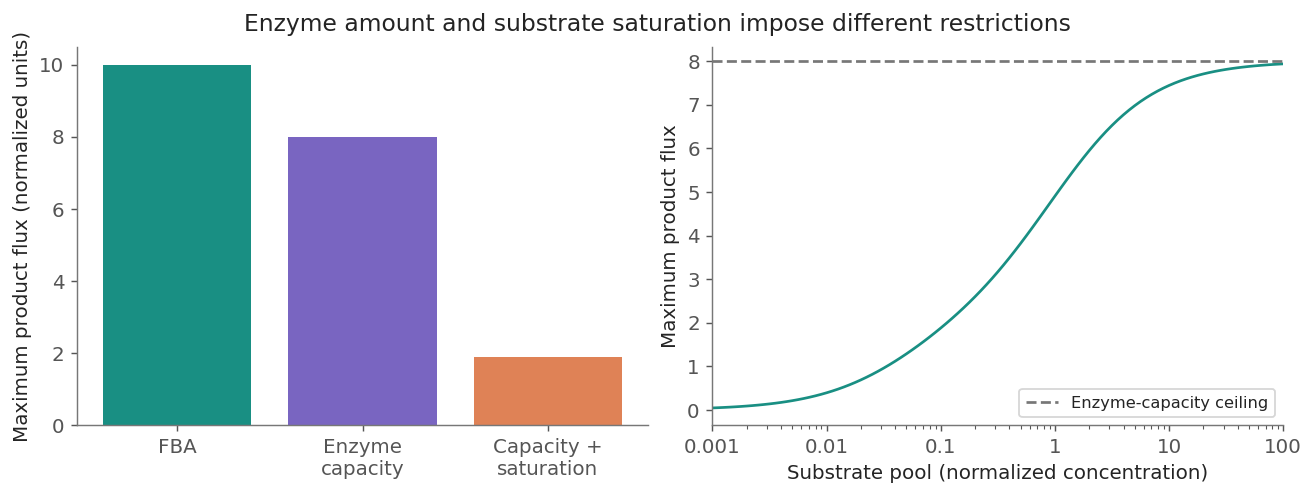

In [31]:
enzyme_cases = [demo.enzyme_fluxes(mode=mode,substrate=.1) for mode in ['fba','enzyme','kinetic']]
display(pd.DataFrame([{'model':d['mode'],'product flux':d['output'],
                      'enzyme 1 flux':d['flux'][1],'enzyme 2 flux':d['flux'][2]} for d in enzyme_cases]).round(5))
substrates = np.logspace(-3,2,101)
outputs = np.array([demo.enzyme_fluxes(substrate=q)['output'] for q in substrates])
figures.enzymes(enzyme_cases,substrates,outputs)
plt.show()

**Experiment:** double enzyme 1, then raise the substrate. These changes relieve different bottlenecks. The uptake cap still limits the answer.

In [32]:
display(pd.DataFrame([{'enzyme 1 amount':e1,'substrate':q,
                      'product flux':demo.enzyme_fluxes(substrate=q,abundance=(e1,.4))['output']}
                     for e1 in [.6,1.2] for q in [.1,10.]]).round(4))

,enzyme 1 amount,substrate,product flux
0,0.6,0.1,1.8788
1,0.6,10.0,7.4446
2,1.2,0.1,2.4242
3,1.2,10.0,10.0000


### A shared enzyme cannot independently run every task at capacity

If the same enzyme serves two conversions, its total required amount is

$$\frac{v_1}{10}+\frac{v_2}{5}\leq E.$$

Set $E=0.6$. With no second task, the first conversion can run at 6. Requiring $v_2\geq1$ consumes 0.2 units of that enzyme and reduces the first conversion's maximum to 4. These are resource-use rows, not chemical consumption of the catalyst.

In [33]:
shared_cases = []
for enzyme_amount in [.6,.9]:
    for second_task in [0.,1.]:
        answer = enzyme_capacity.shared(second_task, enzyme_amount)
        shared_cases.append({'enzyme amount':enzyme_amount,'required second flux':second_task,
                             'maximum first flux':answer['output'],
                             'enzyme used':answer['enzyme_usage']})
display(pd.DataFrame(shared_cases))

,enzyme amount,required second flux,maximum first flux,enzyme used
0,0.6,0.0,6.0,0.6
1,0.6,1.0,4.0,0.6
2,0.9,0.0,9.0,0.9
3,0.9,1.0,7.0,0.9


## 13. A kinetic hybrid can restore selected internal dynamics

To predict the transient of the substrate pool, release its steady-balance constraint. Keep the downstream product balanced and choose maximal output at the concentration-dependent capacities. The two one-way pathways have independent bounds and no shared resource cost here. Product maximization therefore saturates both bounds, fixing $v_i(q)=k_{{\rm cat},i}E_iq/(K_i+q)$. Then

$$\dot q=u-v_1(q)-v_2(q),\qquad \dot B=v_1(q)+v_2(q).$$

Here $B$ is cumulative product, not a population growth rate. The input steps from 1 to 5 at time 3. Immediately after the step, the new input exceeds output, so the internal pool accumulates. The increased pool progressively activates the enzymes. Its state and history now matter.

This is an explicitly constructed kinetic/optimization hybrid. It shows why a statement about all FBA-related methods needs care: conventional dFBA retains internal steady balance, but hybrids can release selected internal balances and integrate them.

Initial internal pool: 0.03366
Final steady pool: 1.06182


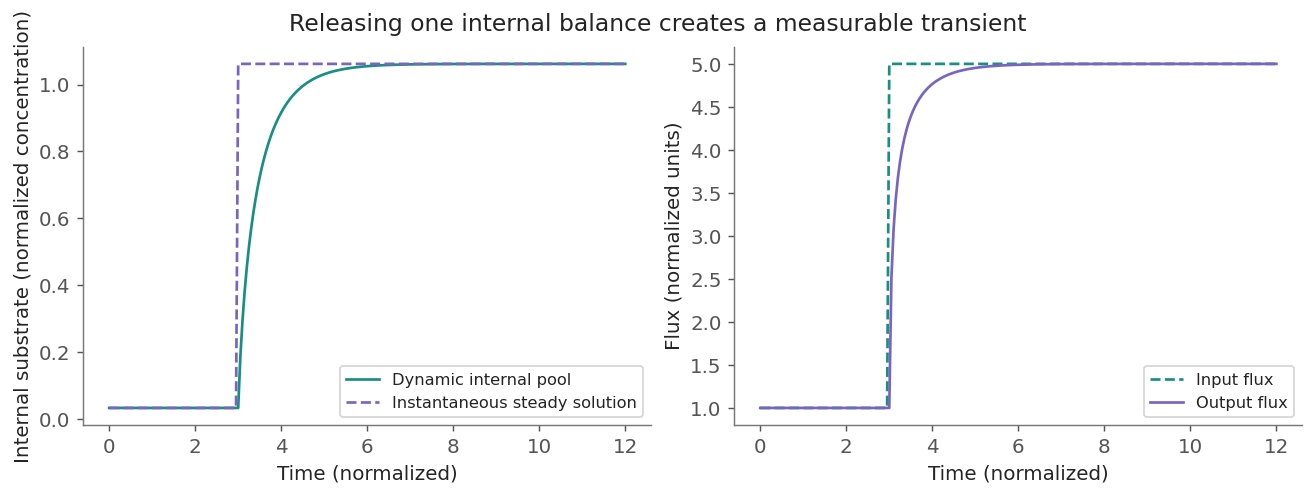

In [34]:
hybrid = demo.hybrid_pool()
print('Initial internal pool:', round(hybrid['initial_pool'],5))
print('Final steady pool:', round(hybrid['final_pool'],5))
figures.hybrid(hybrid)
plt.show()

## 14. Compare descriptions before comparing model size

A mechanistic model composes named processes and states. A constraint-based model selects behavior with physical restrictions and an objective. A learned cellular model fits a mathematical representation from data. These describe different sources of predictive information.

The categories overlap. Karr et al.'s whole-cell model contains an FBA metabolism module. scGPT learns representations from single-cell data. Its learned function does not by itself impose a chemical mass balance. Hybrid models can combine these approaches. Genome coverage alone does not establish which intracellular transients a model can predict.

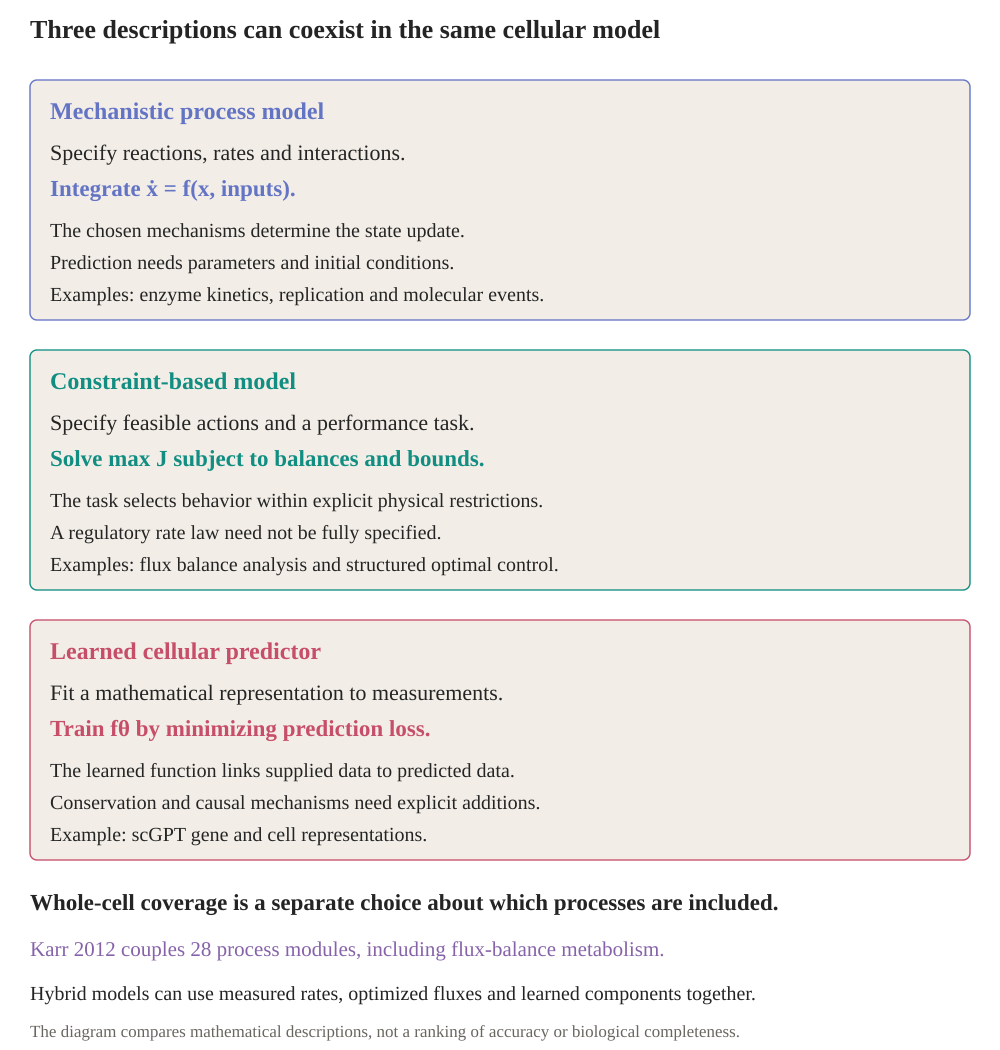

In [35]:
display(SVG(filename=str(HERE / 'figures/cell-model-families.svg')))

## 15. Separate the glycolysis plant from the cart-balancing controller

The nonlinear Hill law belongs to a controller around a catalytic plant. Linearize the Chandra, Buzi and Doyle (2011) example, with intermediate deviation $x_1$, ATP deviation $x_2$, fixed downstream sensitivity $g$, and upstream inhibitory action $u=h x_2$:

$$\dot x=A_gx+b_gu,\quad
A_g=\begin{bmatrix}-\kappa&1+g\\2\kappa&-1-2g\end{bmatrix},\quad
b_g=\begin{bmatrix}-1\\1\end{bmatrix}.$$

The correspondence uses $\begin{bmatrix}\theta\\\omega\end{bmatrix}=Tx$ with
$T=\begin{bmatrix}1&1\\\kappa&-g\end{bmatrix}$.
Then

$$A_c=\begin{bmatrix}0&1\\\kappa&-(\kappa+1+2g)\end{bmatrix},\quad
b_c=\begin{bmatrix}0\\-(\kappa+g)\end{bmatrix},\quad
y_c=\frac{\kappa\theta-\omega}{\kappa+g}.$$

This is the angular plant of a damped inverted pendulum with commanded cart acceleration $(\kappa+g)u$, in a declared nondimensional clock. The matched controller uses $u=h y_c$. ATP corresponds to this angle–velocity combination, not to angle alone. The full force-driven cart with position regulation has four states.

**Change the gain:** compare no feedback, stable feedback and excessive gain in this particular sensor family. The reading core supplies the moving-cart animation. Here we inspect the matrices and both state trajectories.

,angle,angular velocity
angle derivative,-3.489272e-17,1.0
angular acceleration,1.100000e+00,-2.7


Cart input column: [ 0.  -1.4]
Matched cart sensor: [ 0.78571429 -0.71428571]
h = 0.0 closed-loop eigenvalues: [ 0.3595321 -3.0595321]
h = 2.4 closed-loop eigenvalues: [-0.15+1.2318685j -0.15-1.2318685j]
h = 3.1 closed-loop eigenvalues: [0.2+1.50665192j 0.2-1.50665192j]


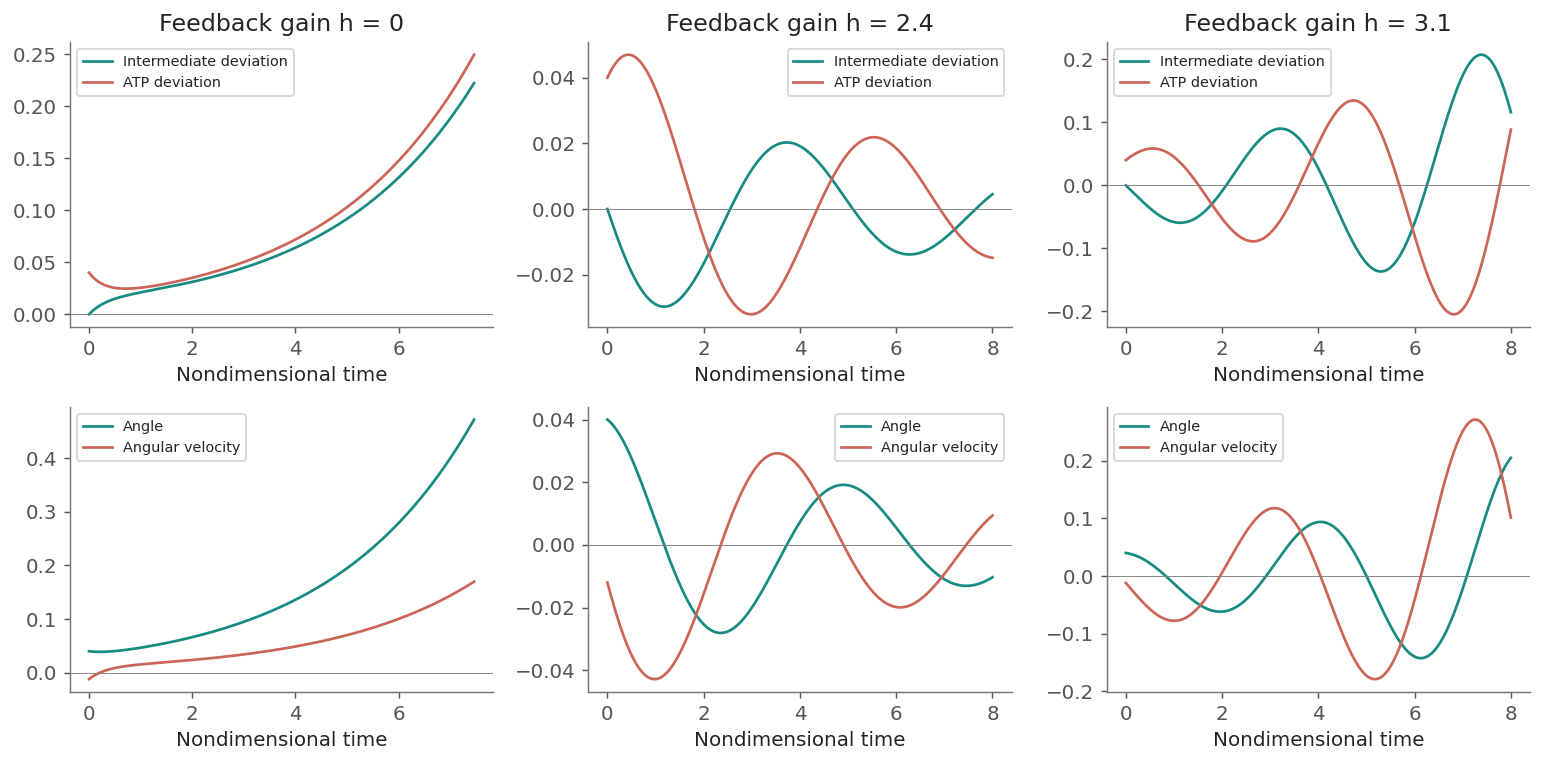

In [36]:
kappa, g = 1.1, .3
Ag = np.array([[-kappa,1+g],[2*kappa,-1-2*g]])
bg = np.array([[-1.],[1.]])
Cg = np.array([[0.,1.]])
T = np.array([[1.,1.],[kappa,-g]])
Ac, bc, Cc = T@Ag@np.linalg.inv(T), T@bg, Cg@np.linalg.inv(T)
display(pd.DataFrame(Ac,index=['angle derivative','angular acceleration'],
                     columns=['angle','angular velocity']))
print('Cart input column:', bc.ravel())
print('Matched cart sensor:', Cc.ravel())
time = np.linspace(0,8,401)
initial_x = np.array([0.,.04])
fig, axes = plt.subplots(2,3,figsize=(12,6))
for j,h in enumerate([0.,2.4,3.1]):
    closed = Ag + h*bg@Cg
    states = np.array([expm(closed*t)@initial_x for t in time])
    visible = np.maximum.accumulate(np.max(np.abs(states),axis=1)) <= .25
    states, t = states[visible], time[visible]  # local linear range only
    cart = states@T.T
    for ax,values,labels in [(axes[0,j],states,['Intermediate deviation','ATP deviation']),
                            (axes[1,j],cart,['Angle','Angular velocity'])]:
        for i,color in enumerate(['#168b82','#cc6556']):
            ax.plot(t,values[:,i],color=color,label=labels[i])
        ax.axhline(0,color='gray',linewidth=.5)
        ax.legend(fontsize=8)
        ax.set_xlabel('Nondimensional time')
    axes[0,j].set_title(f'Feedback gain h = {h:g}')
    print('h =',h,'closed-loop eigenvalues:', np.linalg.eigvals(closed))
    assert np.allclose(T@closed@np.linalg.inv(T),Ac+h*bc@Cc)
fig.tight_layout()
plt.show()

## 16. Flux exponent control: retain the catalytic plant and choose activities

The glycolysis example has two evolving internal pools, intermediate $q_I$ and ATP $q_A$:

$$\dot q=S v+\begin{bmatrix}0\\-w\end{bmatrix},\quad
S=\begin{bmatrix}1&-1\\-1&2\end{bmatrix},\quad
v_1=2q_Au_1,\quad v_2=2\kappa q_Iu_2,\quad\kappa=1.1.$$

The catalytic substrate dependences remain. We optimize multiplicative activities $u_1,u_2$ without specifying the Hill feedback laws. The finite-horizon objective penalizes log-concentration tracking error and changes of log activity. The weights, horizon and targets follow the archived 2023 notebook reproduction. Here the demand step is synchronized to time zero and starts from an exact equilibrium.

Demand rises from 1 to 1.1. The chosen target is $\begin{bmatrix}1/\kappa+0.07&0.93\end{bmatrix}^{T}$. That target shift is an explicit task assumption. It is not inferred from stoichiometry. State floors are checked. The fast quadratic solve is used only while they remain inactive. No activity ceiling or explicit binding-order polytope is imposed in this particular reproduction.

The optimized activities are not themselves reaction exponents. Binding structure constrains how activities can depend on concentrations in the full flux exponent control theory. This experiment demonstrates structured dynamic optimization and oscillatory transients, not recovery of a unique molecular mechanism.

,activity-change penalty,minimum ATP,minimum predicted ATP,quadratic stationarity residual
0,3.0,0.881966,0.867106,2.870967e-16
1,5.5,0.862763,0.851955,4.976488e-16


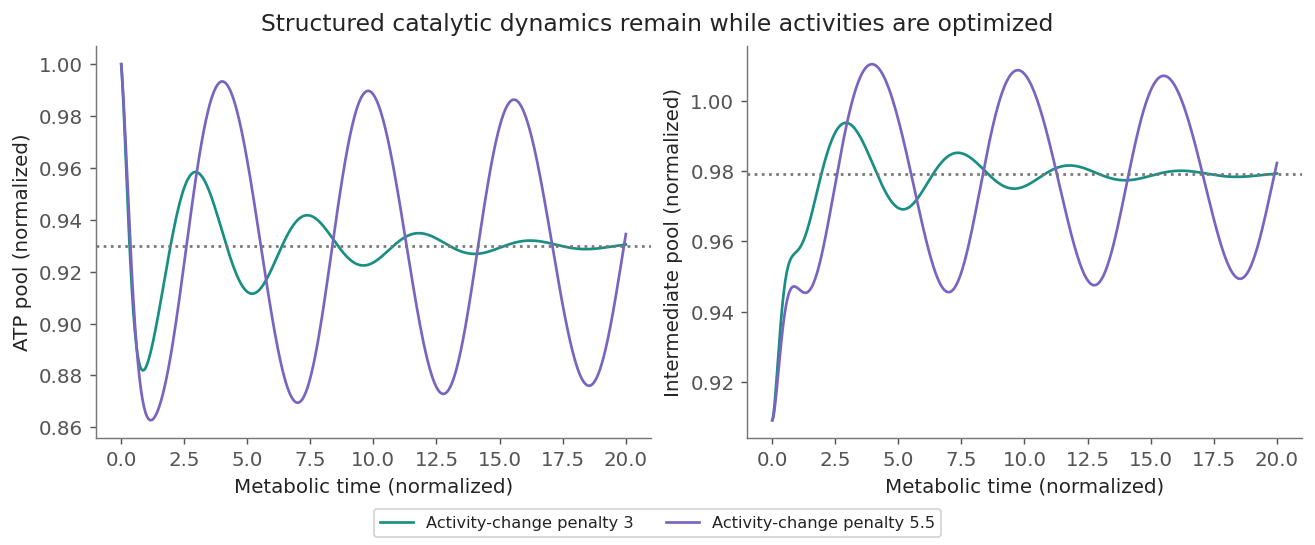

In [37]:
fec_curves = [fec_tracking.simulate(penalty=p) for p in [3.,5.5]]
display(pd.DataFrame([{'activity-change penalty':d['penalty'],
                      'minimum ATP':d['q'][:,1].min(),
                      'minimum predicted ATP':d['predicted_minimum'][1],
                      'quadratic stationarity residual':d['stationarity_max']} for d in fec_curves]))
figures.fec(fec_curves)
plt.show()

**Check what FBA would erase.** A balanced flux vector would require $Sv+\begin{bmatrix}0\\-w\end{bmatrix}=0$ at every time. The chosen activities instead produce a nonzero pool derivative during the transient. Read one entry directly.

In [38]:
run = fec_curves[0]
index = np.searchsorted(run['t'],1.0)
q = run['q'][index]
u = run['activity'][index]
v = fec_tracking.flux(q,u)
display(pd.Series({'time':run['t'][index], 'intermediate':q[0], 'ATP':q[1],
                   'upstream activity':u[0], 'downstream activity':u[1],
                   'intermediate derivative':(fec_tracking.S@v)[0],
                   'ATP derivative':(fec_tracking.S@v)[1]-run['demand']}))

time                       1.020000
intermediate               0.957545
ATP                        0.884149
upstream activity          0.647279
downstream activity        0.539293
intermediate derivative    0.008508
ATP derivative             0.027566
dtype: float64

## 17. Maximize final biomass while preserving metabolic viability

Start with $\dot N=(\mu-d)N$. For a fixed positive initial biomass, maximizing $N(T)$ is equivalent to maximizing $\int_0^T(\mu-d)\,dt$. An absolute production flux is $\mu N$, not $\mu$. Discounting the running growth reward changes the task. Multiplying a fixed terminal reward by $e^{-\delta T}$ does not.

The following new normalized glycolysis model tests growth arrest using a pure terminal-biomass objective:

$$v_1=A^{-2}u_1,\quad v_2=2I,\quad v_g=A u_g,\quad\mu=0.1v_g,$$
$$\dot I=v_1-v_2-\mu I,\quad
\dot A=-v_1+2v_2-v_g-w-\mu A,\quad\dot N=\mu N.$$

Demand rises from 0.6 to 1.4. The payoff activity is fixed. Controls have bounds $10^{-4}\leq u_1\leq1$ and $0\leq u_g\leq1$. An ATP floor is a viability constraint. There is no ATP-tracking penalty.

These saved multiple-shooting solutions use a four-unit horizon and 0.1-unit control intervals. Independent integration and a halved control interval verify the qualitative arrest. They are candidate numerical optima for a teaching model, not a fitted biological response or proof of a global optimum.

,case,final_biomass,log_biomass,minimum_atp,arrest_duration,initial_growth_activity
0,floor_0.75,1.121738,0.114879,0.7501,0.5,0.300476
1,floor_0.8,1.061307,0.059501,0.8001,0.6,0.022772
2,floor_0.75_active,1.117522,0.111114,0.7501,0.0,0.113102


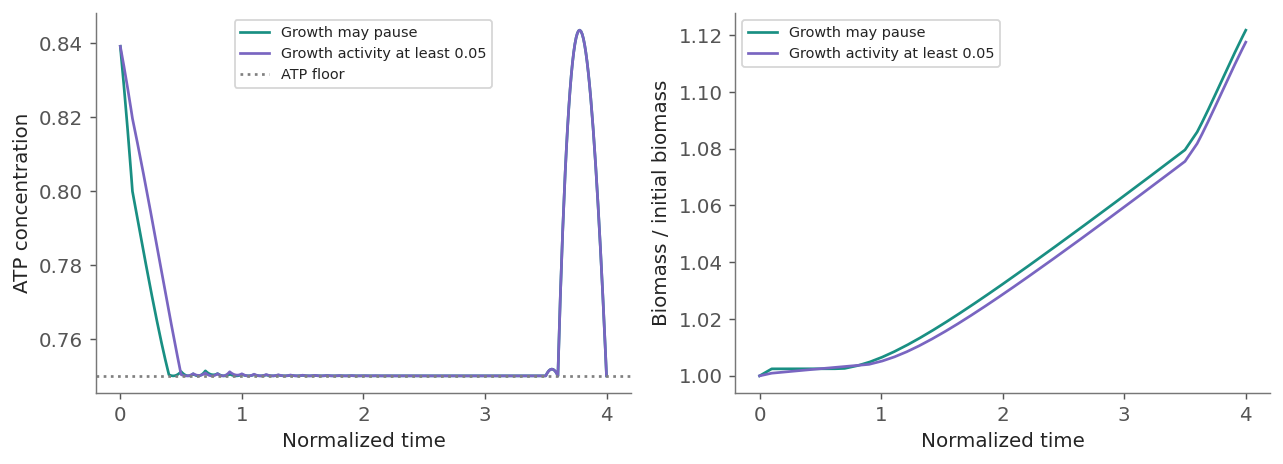

In [39]:
growth_results = json.loads((HERE / 'data/glycolysis-results.json').read_text())
display(pd.DataFrame([{'case':name, **r['summary']} for name,r in growth_results.items()]))
fig, axes = plt.subplots(1,2,figsize=(10,3.7))
for name in ['floor_0.75','floor_0.75_active']:
    r = growth_results[name]
    label = 'Growth may pause' if name == 'floor_0.75' else 'Growth activity at least 0.05'
    axes[0].plot(r['t'], np.asarray(r['x'])[:,1], label=label)
    axes[1].plot(r['t'], r['biomass'], label=label)
axes[0].axhline(.75,color='gray',linestyle=':',label='ATP floor')
axes[0].set(xlabel='Normalized time',ylabel='ATP concentration')
axes[1].set(xlabel='Normalized time',ylabel='Biomass / initial biomass')
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
RECOMPUTE_GROWTH = False  # this solve is slower than the earlier LPs
if RECOMPUTE_GROWTH:
    new_growth = growth_control.optimize(atp_floor=.75,substeps=10)
    display(pd.Series(new_growth['summary']))

## 18. Let growth manufacture its own machinery

The allocation model contains precursor amount $P$, metabolic protein $E$ and ribosomal protein $R$. Set $N=E+R$, $q=P/N$, and $\phi=R/N$. Metabolic protein imports precursor at $v_{\rm in}=\alpha E$. Ribosomal protein produces new protein at $v_{\rm syn}=\beta(q)R$, with $\beta(q)=3q/(0.1+q)$. The control $\rho$ allocates new protein to ribosomes:

$$\dot P=v_{\rm in}-v_{\rm syn},\quad
\dot E=(1-\rho)v_{\rm syn},\quad\dot R=\rho v_{\rm syn}.$$
$$\dot q=\alpha(1-\phi)-\mu(1+q),\quad
\dot\phi=\mu(\rho-\phi),\quad\mu=\beta(q)\phi.$$

A carbon shift changes $\alpha$. It does not instantly change the precursor or protein state. Choose $0\leq\rho\leq1$ to maximize final biomass, subject to $q\geq0.02$ and $0.02\leq\phi\leq0.98$. No death, protein degradation or other biomass sectors are modeled.

**Solve a short experiment live:** change `horizon` or exchange the before/after uptake capacities. The optimizer runs here, rather than loading this short result from a file.

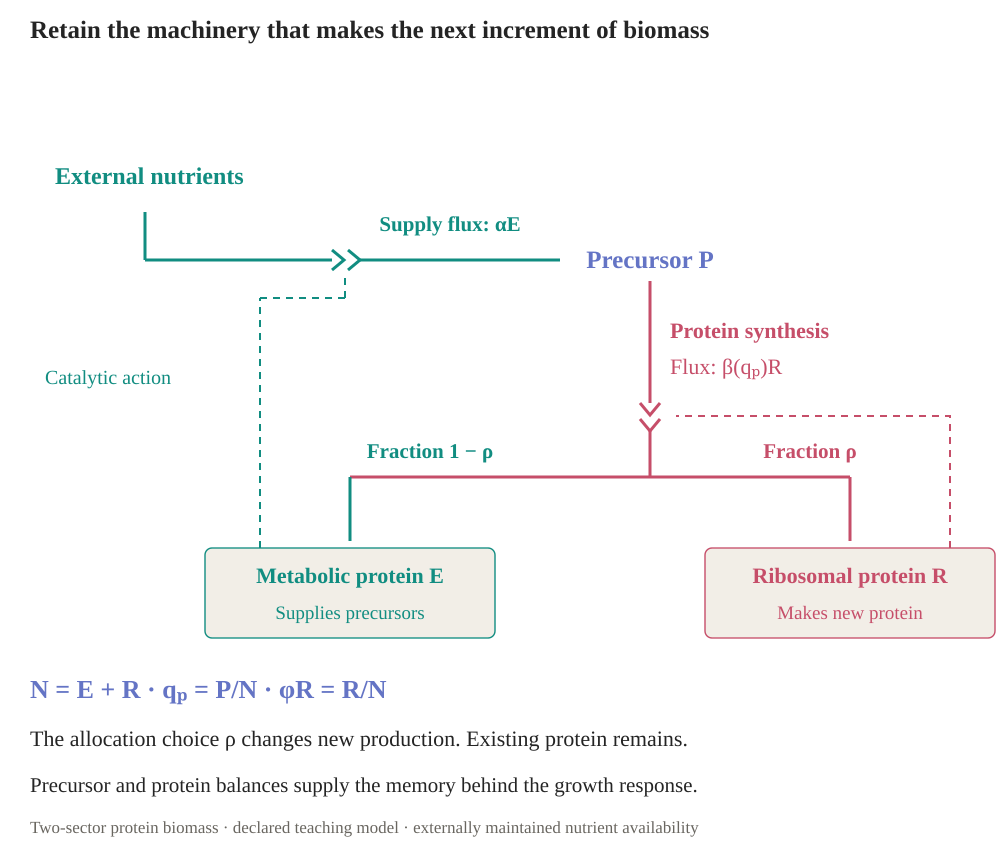

final_biomass                 3.808122
integrated_specific_growth    1.337136
reward                        1.337136
initial_allocation            1.000000
minimum_precursor             0.061396
minimum_ribosomal_fraction    0.153846
final_precursor               0.061396
final_ribosomal_fraction      0.584545
dtype: float64

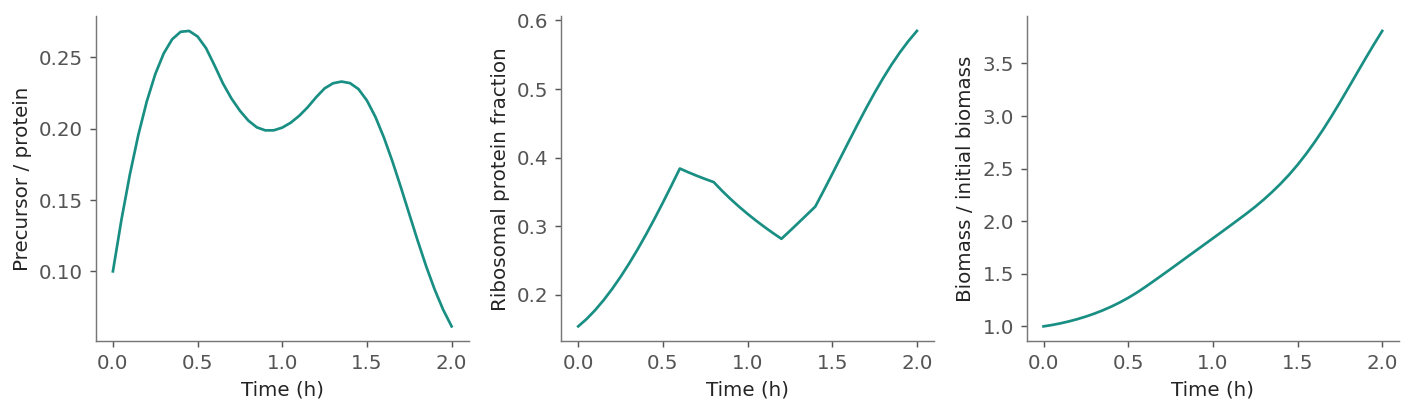

In [40]:
display(SVG(filename=str(HERE / 'figures/allocation-plant.svg')))
horizon = 2.0
before, after = .3, 1.2
short_allocation = allocation_control.optimize(before,after,horizon=horizon)
display(pd.Series(short_allocation['summary']))
fig, axes = plt.subplots(1,3,figsize=(11,3.3))
x = np.asarray(short_allocation['x'])
axes[0].plot(short_allocation['t'],x[:,0])
axes[1].plot(short_allocation['t'],x[:,1])
axes[2].plot(short_allocation['t'],short_allocation['biomass'])
for ax,label in zip(axes,['Precursor / protein','Ribosomal protein fraction','Biomass / initial biomass']):
    ax.set(xlabel='Time (h)',ylabel=label)
fig.tight_layout()
plt.show()

### Compare horizons and the value assigned to future growth

The longer saved solves compare two- and eight-hour horizons, plus the running reward $\int_0^T e^{-\delta t}\mu(t)\,dt$ with $\delta=2\ {\rm h}^{-1}$. The same dynamic plant supports different preferred allocations. After a downshift, the eight-hour final-biomass objective initially favors metabolic protein. Strong discounting initially favors ribosomal protein.

End-of-horizon resource spending is part of a finite task. It is not a new steady-growth law. Very late controls under strong discounting are weakly determined. Thiermann et al. (2026) measured different growth and stress responses in *E. coli* and *B. subtilis*. Their translation-inhibition experiment does not identify these discount factors and is not a carbon-shift fit.

,case,final_biomass,integrated_specific_growth,reward,initial_allocation,minimum_precursor,minimum_ribosomal_fraction,final_precursor,final_ribosomal_fraction
0,upshift_T8_discount0,207.918602,5.337147,5.337147,1.000000e+00,0.061077,0.153846,0.061077,0.585771
1,upshift_T8_discount2,163.833146,5.098849,0.278781,1.000000e+00,0.091781,0.153846,0.204318,0.329443
2,upshift_T2_discount0,3.808122,1.337136,1.337136,1.000000e+00,0.061396,0.153846,0.061396,0.584545
3,downshift_T8_discount0,7.037220,1.951213,1.951213,3.616604e-17,0.027291,0.125379,0.027291,0.359176
4,downshift_T8_discount2,6.018143,1.794779,0.202628,1.000000e+00,0.022111,0.228812,0.045892,0.228812
5,downshift_T2_discount0,1.767423,0.569523,0.569523,1.950067e-16,0.028700,0.226708,0.028700,0.333867


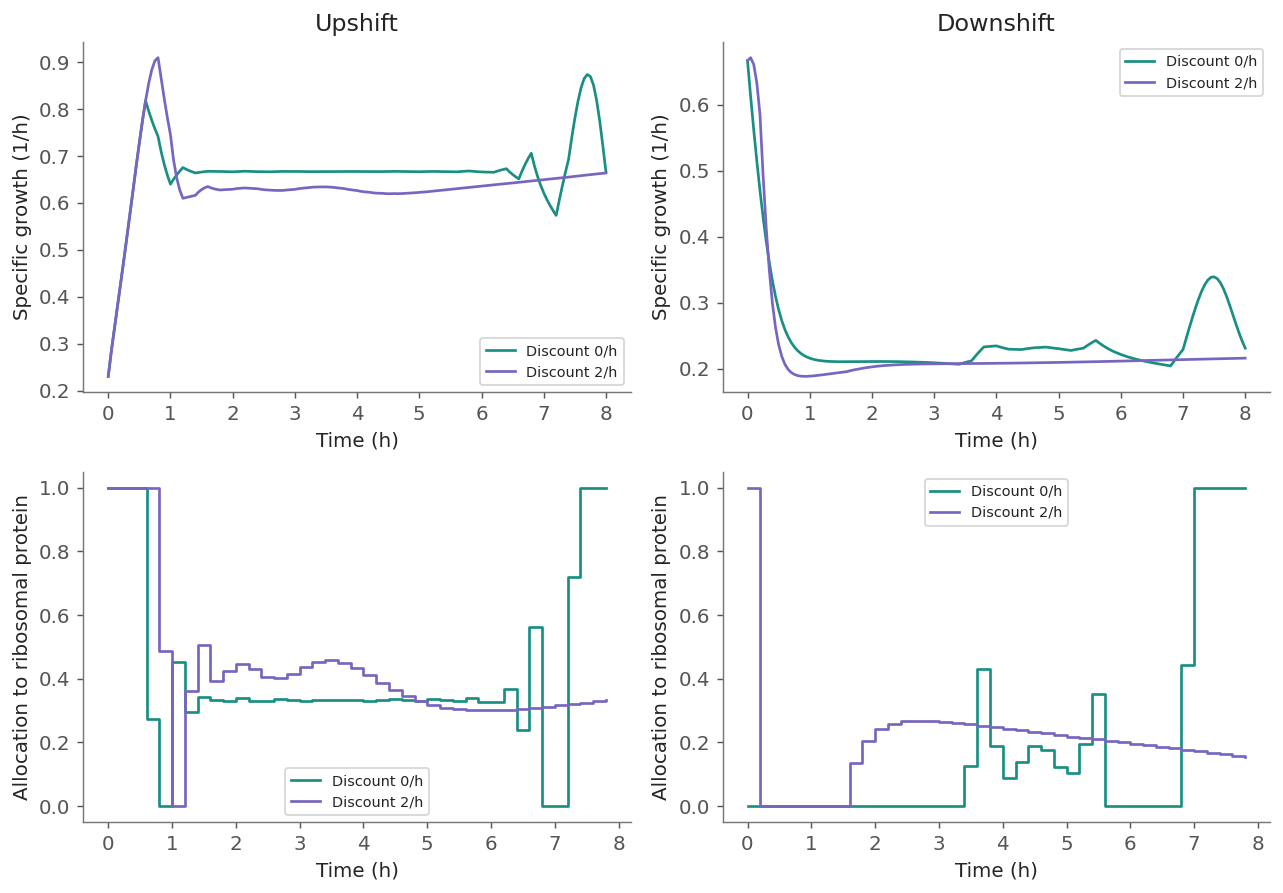

In [41]:
allocation_results = json.loads((HERE / 'data/allocation-results.json').read_text())
display(pd.DataFrame([{'case':name, **r['summary']} for name,r in allocation_results.items()
                      if 'summary' in r]))
fig, axes = plt.subplots(2,2,figsize=(10,7))
for j,shift in enumerate(['upshift','downshift']):
    for discount in [0,2]:
        r = allocation_results[f'{shift}_T8_discount{discount}']
        axes[0,j].plot(r['t'],r['growth'],label=f'Discount {discount}/h')
        control_time = np.arange(len(r['rho']))*r['interval']
        axes[1,j].step(control_time,r['rho'],where='post',label=f'Discount {discount}/h')
    axes[0,j].set_title(shift.capitalize())
    axes[0,j].set_ylabel('Specific growth (1/h)')
    axes[1,j].set_ylabel('Allocation to ribosomal protein')
    for ax in axes[:,j]:
        ax.set_xlabel('Time (h)')
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
RECOMPUTE_ALLOCATION = False
if RECOMPUTE_ALLOCATION:
    changed_objective = allocation_control.optimize(1.2,.3,horizon=8,discount=2)
    display(pd.Series(changed_objective['summary']))

## Source and model notes

The detailed equations, parameter status, references and verification are in `MODEL-NOTES.md` and `verification.json`. Starting sources include Orth et al. (2011) for iJO1366, Mahadevan et al. (2002) for dynamic FBA, Basan et al. (2015) and Mori et al. (2016) for allocation constraints, Mori et al. (2017) for reserve-dependent rich-medium recovery, Erickson et al. (2017) for carbon-shift kinetics, Henry et al. (2007) for thermodynamic consistency, Sánchez et al. (2017) for enzyme constraints, Covert et al. (2008) for kinetic hybrids, Xiao, Li and Doyle (2023) for flux exponent control, and Khazaei et al. (2020) for community multistability. The offline model JSON files were archived from BiGG on 13 October 2026 and copied unchanged into this package.

COBRApy API documentation: [object inspection and bound resets](https://cobrapy.readthedocs.io/en/latest/getting_started.html), [local JSON loading](https://cobrapy.readthedocs.io/en/latest/io.html), and [dynamic FBA](https://cobrapy.readthedocs.io/en/latest/dfba.html). These links are optional reading. The notebook itself runs offline after its Python dependencies are installed.

Additional sources: Chandra, Buzi and Doyle (2011) for the glycolytic plant and feedback limitation. Feist and Palsson (2010) for biomass accounting. Greinert et al. (2021), Table 1, for the activity-based hexokinase standard reaction energy. Karr et al. (2012) and Cui et al. (2024) for the model-family comparison. Thiermann et al. (2026) for the distinct bacterial growth and stress architectures.

`STAGED-MODEL-NOTES.md` records the new model boundaries, result files and checks. The culture-protocol, mass, enzyme-sharing and growth-control calculations are new teaching calculations. The full texts and detailed reading records stay in the course literature archive.
